# EA: Vergleich Unterschiedlicher ML-Verfahren für die Vorhersage mehrerer Zielgrößen

### Wahl des Datensatzes
https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set

**Beschreibung**
> - Gas Turbine CO and NOx Emission Data Set
> - Beobachtung eine Gasturbinenanlage in der Turkei
> - Zeitraum von 01.01.2011 bis 31.12.2015
> - 36733 Instanzen, eine Instanz = Mittelwert Sensorendaten über eine Stunde
> - Features:
>   - Kategorisch:
>     - Jahr (year)
>   - Numerisch:
>     - Umgebungstemperatur (AT)
>     - Umgebungsdruck (AP)
>     - Luftfeuchtigkeit (AH)
>     - Differenzdruck am Luftfilter (AFDP)
>     - Abgasdruck der Gasturbine (GTEP)
>     - Eintrittstemperatur in Turbine (TIT)
>     - Austrittstemperatur nach Turbine(TAT)
>     - Austrittsdruck des Kompressors (CDP)
> - Targets (Numerisch):
>   -  Energieertrag (TEY) (Optional)
>   -  Kohlenmonoxid Emissionen (CO)
>   -  Stickoxid Emissionen (NOX)

**Begründung**
> - Groß genug für Sinnvolles Training (36733 Instanzen)
> - continuous Features aus echten Sensordaten in sinnvollen Werterahmen
> - regression mit continuous Features eignet sich für Neural Network
> - durch mehrere Targets Vergleich unterschiedlicher ML-Verfahren:
>   - pro Target ein Decision Tree
>   - pro Target ein Neural Network
>   - ein Multi Output Neural Network mit 3 Output Neuronen

### Preprocessing Part 1:
> - Beschaffung und grundlegende Aufbereitung der Daten
> - nur soweit, dass sie theoretisch zum trainieren von ML-Verfahren genutzt werden können
> - keine Optimierung

In [15]:
# Select torch backend
import os
os.environ["KERAS_BACKEND"] = "torch"

In [ ]:
#pip install ucimlrepo torch

In [16]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import numpy as np
  
# fetch dataset 
gas_turbine_co_and_nox_emission_data_set = fetch_ucirepo(id=551) 
  
# data (as pandas dataframes) 
data = gas_turbine_co_and_nox_emission_data_set.data.features 

targets = data[["TEY", "CO", "NOX"]]
features = data.drop(columns=["TEY", "CO", "NOX"])

#### Missing Values Prüfung:

In [17]:
print(data.isnull().sum())

year    0
AT      0
AP      0
AH      0
AFDP    0
GTEP    0
TIT     0
TAT     0
TEY     0
CDP     0
CO      0
NOX     0
dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

x_train_raw, x_test_raw, y_train_raw, y_test_raw = train_test_split(features, targets, test_size=0.2, shuffle=True, random_state=42)

## Preprocessing Part 2:

> - Visualisierung und Analyse der Variablen
> - prüfen auf Outlier und Korrelation
> - Umgang mit Kategorischen Features
> - Skalierung


### Feature Verteilung und Prüfung auf Outlier

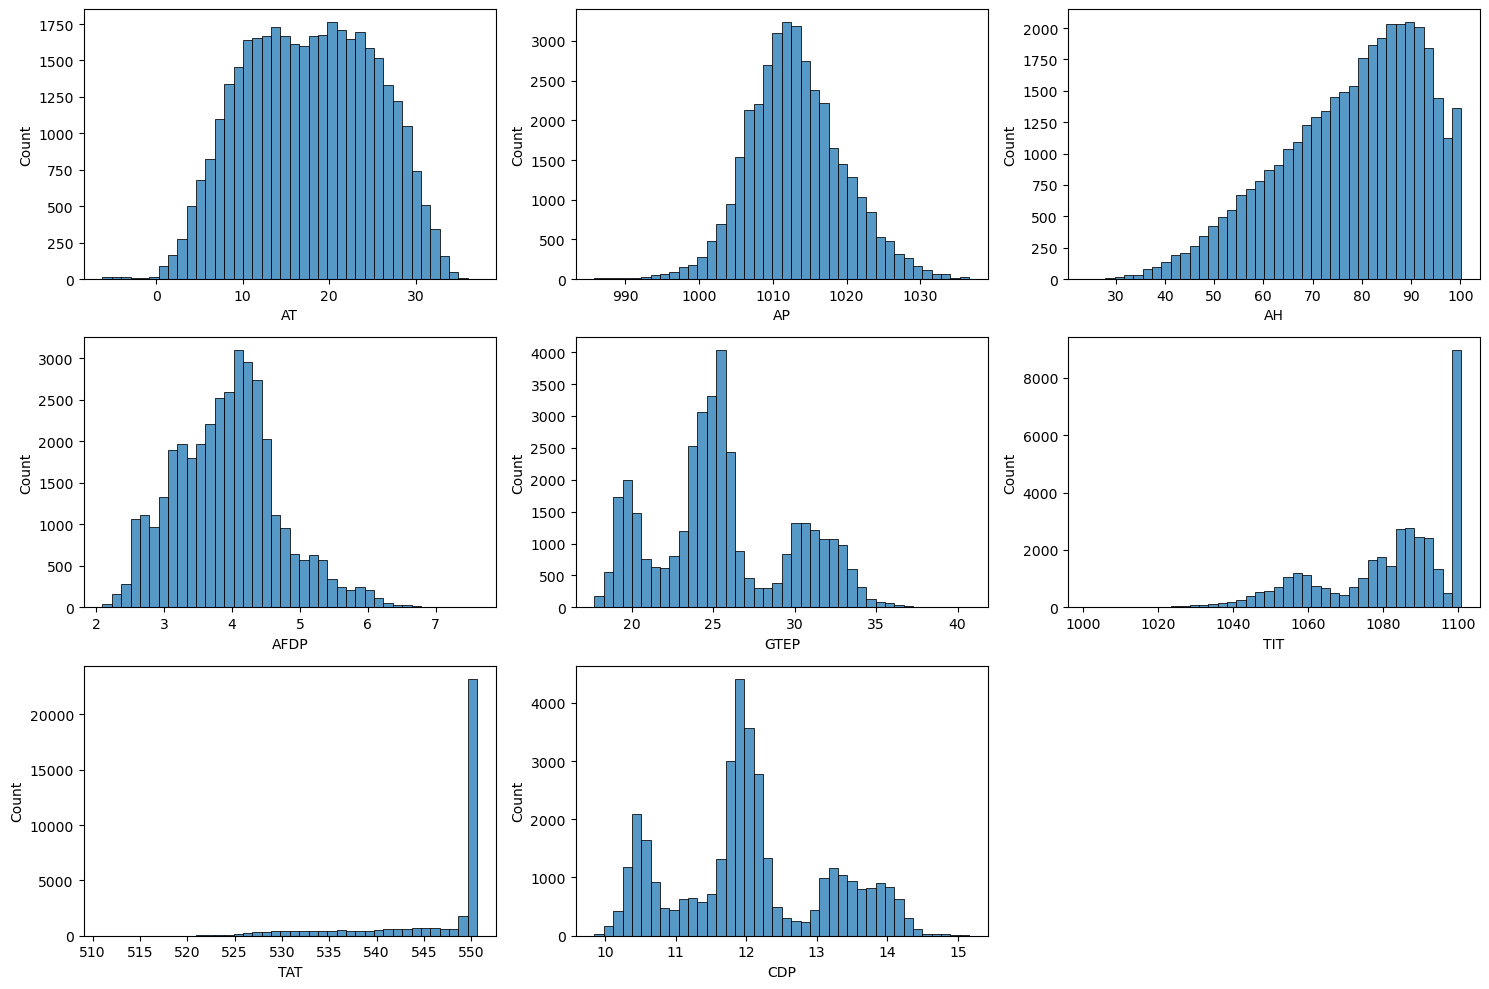

In [19]:
import matplotlib.pyplot as plt
import seaborn

plt.figure(figsize=(15, 10))

for i, col in enumerate(features.drop(columns=["year"])):
    plt.subplot(3, 3, i+1)
    seaborn.histplot(features[col], bins=40)

plt.tight_layout()
plt.show()

#### Interpretation

> - Wertebereiche plausibel
> - Keine offensichtlichen ausreißer -> kein Handlungsbedarf
> - AT unter 0 -> Umgebungstemperatur
> - CDP und GTEP sehr ähnlich

### Target Verteilungen

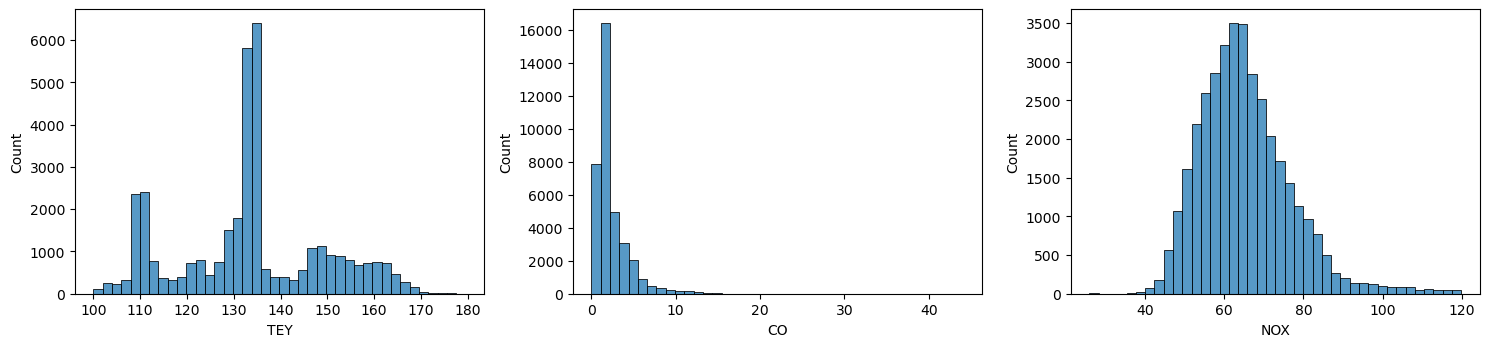

In [20]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(targets):
    plt.subplot(3, 3, i+1)
    seaborn.histplot(targets[col], bins=40)

plt.tight_layout()
plt.show()

#### Interpretation

> - TEY hat Zewi Peaks und dadurch eine mögliche Fallhöhe in der Unterscheidung
> - CO hat sehr viele, eher niedrige Werte und deutlich weniger höhere, dadurch im Training deutlich weniger Beispiele und möglicher weise schwere Prediction
> - NOX annähernd glockenförmig, weniger extrem seltene bereiche. Kann Schwierigkeiten bei Werten von 100 bis 120 bekommen

### Prüfung auf Korrelation

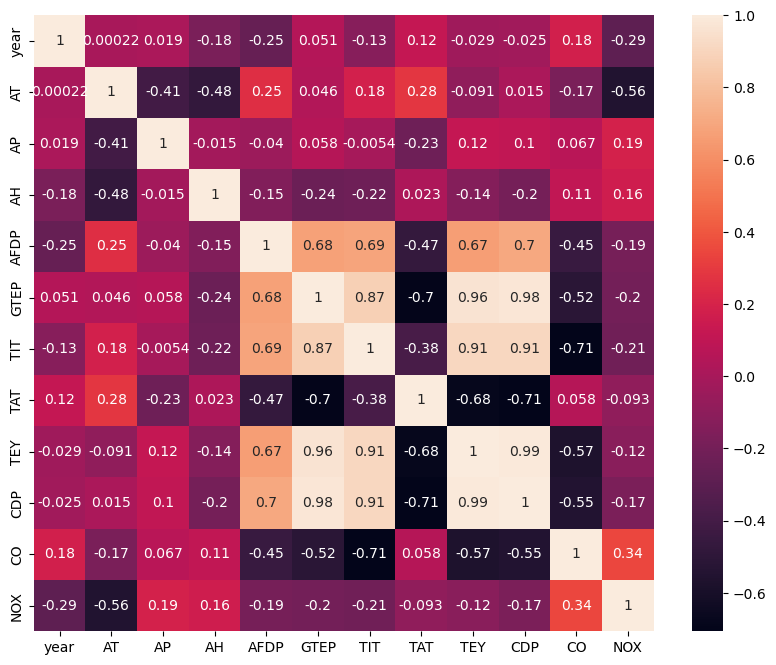

In [21]:
corr_matrix = data.corr(numeric_only=True)

fig2 = plt.figure(figsize=(10,8))

ax = fig2.add_subplot()
ax = seaborn.heatmap(corr_matrix, annot=True)

fig2.show()

#### Interpretation
> - Energieertrag korreliert stark mit Austrittsdruck des Kompresssors und abgasdruck der Turbine (physikalisch starke Abhängigkeit, kein Dataleak)
> - CO und NOX korrelieren deutlich weniger mit den features
> - CDP und GTEP korrelieren stark -> haben sehr ähnliche Aussagekraft -> feature für weniger komplexität entfernen
> - korrelation zwischen Targets erkennbar, möglicher Vorteil multi output NN

In [22]:
features = features.drop(columns=["CDP"])

### Umgang mit kategorischen Feature

> - korreliert vergleichsweise wenig mit Targets, aber nicht 0
> - Int -> keine Umwandlung nötig
> - modellieren von zeitlichen Abstand sinnvoll
> - weil nur vverschiedene ML-Verfahren verglichen werden sollen und in Zukunft keine aktuellen Daten mit neuen Jahren getestet werden sollen, behalten

In [23]:
print(features["year"].unique())

[2011 2012 2013 2014 2015]


### Train Test split für preprocessed data ohne Skalierung

In [24]:
x_train_processed, x_test_processed, y_train_processed, y_test_processed = train_test_split(features, targets, test_size=0.2, shuffle=True, random_state=42)


In [25]:
print(x_train_processed.min())
print()
print(x_train_processed.max())

year    2011.0000
AT        -6.2348
AP       986.2500
AH        25.9870
AFDP       2.0874
GTEP      17.6980
TIT     1000.8000
TAT      511.0400
dtype: float64

year    2015.0000
AT        35.8220
AP      1036.6000
AH       100.2000
AFDP       7.5549
GTEP      40.7160
TIT     1100.9000
TAT      550.6100
dtype: float64


## Feature Scaling (Standardisierung)

Da die Eingabefeatures sehr unterschiedliche Größenordnungen besitzen (z. B. AP ~ 1000, AT ~ 20), werden sie mit **StandardScaler** standardisiert.

**Ziel:**  
Das alle Features einen Mittelwert von 0 und eine Standardabweichung von 1 haben.

### Warum ist das wichtig?
Neuronale Netze reagieren empfindlich auf unterschiedliche Skalen. Ohne Skalierung würden große Werte (z. B. TIT oder AP) die Modellberechnung dominieren und das Training destabilisieren.

Beispiel:

AP:   0.1 x 985  = 98.5  
TIT:  0.1 × 1000 = 100.0  
AT:   0.1 ×   20 =   2.0  
AFDP: 0.1 ×    4 =   0.4  

### Ergebnis
Nach der Standardisierung liegen alle Features in einem vergleichbaren Wertebereich, was zu stabilerem und schnellerem Training führt.

In [26]:
from sklearn.preprocessing import StandardScaler

# Scaler auf Trainingsdaten trainieren
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_processed)
x_test_scaled = scaler.transform(x_test_processed)

In [27]:
pd.DataFrame(x_train_scaled, columns=x_train_processed.columns).describe()

,year,AT,AP,AH,AFDP,GTEP,TIT,TAT
count,2.938600e+04,2.938600e+04,2.938600e+04,2.938600e+04,2.938600e+04,2.938600e+04,2.938600e+04,2.938600e+04
mean,-2.970807e-14,2.272886e-17,1.312676e-14,-1.034647e-15,2.369604e-17,3.917101e-17,4.609605e-15,-1.612298e-15
std,1.000017e+00,1.000017e+00,1.000017e+00,1.000017e+00,1.000017e+00,1.000017e+00,1.000017e+00,1.000017e+00
min,-1.402823e+00,-3.223967e+00,-4.160572e+00,-3.601857e+00,-2.367984e+00,-1.871945e+00,-4.591652e+00,-5.141304e+00
25%,-6.960478e-01,-7.961349e-01,-6.577809e-01,-6.668328e-01,-7.365906e-01,-5.888194e-01,-5.584913e-01,-2.147791e-01
50%,1.072693e-02,1.427325e-02,-6.751005e-02,1.831526e-01,1.575864e-02,-1.075506e-01,2.561160e-01,5.446399e-01
75%,7.175017e-01,8.001837e-01,6.004280e-01,7.918075e-01,5.850030e-01,8.421229e-01,8.884337e-01,5.680630e-01
max,1.424276e+00,2.436984e+00,3.660516e+00,1.542069e+00,4.673517e+00,3.611458e+00,1.110599e+00,6.515076e-01


### **Ergebnis:**  
Mittelwert ca. bei 0 und die Standardabweichung ca. bei 1

## Baseline Model
> - Orientierungspunkt für die Einschätzung der stärke einzelner Modelle

In [28]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


baseline = DummyRegressor(strategy="mean")

baseline.fit(x_train_scaled, y_train_processed)
y_pred = baseline.predict(x_test_scaled)

rmses = root_mean_squared_error(y_test_processed, y_pred, multioutput="raw_values")
maes = mean_absolute_error(y_test_processed, y_pred, multioutput='raw_values')

baseline_rmse = pd.DataFrame({
        "target": y_train_processed.columns,
        "rmse": rmses
    })

baseline_mae = pd.DataFrame({
    "target": y_train_processed.columns,
    "mae": maes
})

print(baseline_rmse)
print()
print(baseline_mae)

  target       rmse
0    TEY  15.611770
1     CO   2.331885
2    NOX  11.511902

  target        mae
0    TEY  11.513038
1     CO   1.415037
2    NOX   8.837000


# Vergleich der ML Verfahren

## DecisionTreeRegressor (CART)
> - warum?
>   - Starker nicht NN Algorithmus für Regression
>   - gut geeignet als Baseline für NN 
>   - Vorteil: nachvollziehbare Entscheidungsfindung
>   - deutlich ressourcenschohnender als NN 

### Parameter, nach denen optimiert wird:
> - max_depth (Standard=None)
>   - Begrenzung der maximalen Ebenen des Baums
> - min_samples_leaf (Standard=1)
>   - Minimale Anzahl an Samples, die in jedem Blatt übrig bleiben müssen, damit Split durchgeführt wird
> - ccp_alpha (Standard=0.0)
>   - Cost Complexity Pruning: Entfernen von Teilbäumen mit geringem Mehrwert nach Training
>   - Für alle Teilbaume prüfen: wie stark erhöht Fehler, wenn Teilbaum durch Blatt ersetzt 
>   - Betrachtung in Verhältniss zu eingesparter Baumkomplexität
>   -  ccp_alpha -> Faktor, je größer, desto mehr Fehler wird tolleriert zugunsten von einem weniger komplexen Baum

### Vorgehen:
> - Optimierung auf RMSE
> - Für jeden Parameter Range an besten Werten bestimmen
> - Anschließend Beste Kombination der Parameter finden

### Hilfsmethoden

#### eval_param: Gibt für gegebene Werte eines Parameters RMSE auf train und testset eines mit dem Parameter trainierten Modells zurück

In [29]:
def eval_param(param_name, param_values, x_train, y_train, x_test, y_test):
    train_results = []
    test_results = []

    for val in param_values:

        clf = tree.DecisionTreeRegressor(**{param_name: val}, random_state=42)
        clf.fit(x_train, y_train)

        pred_train = clf.predict(x_train)
        pred_test = clf.predict(x_test)

        rmse_train = root_mean_squared_error(y_train, pred_train)
        rmse_test = root_mean_squared_error(y_test, pred_test)

        train_results.append({
            param_name: val,
            "rmse": rmse_train
        })

        test_results.append({
            param_name: val,
            "rmse": rmse_test
        })

    return pd.DataFrame(train_results), pd.DataFrame(test_results)

#### plot_eval_res: Erstellt Grafik zur visuellen Darstellung der RMSE Verläufe

In [30]:
def plot_eval_res(train_df, test_df, baseline_rmse, param_name, xticks):
    fig = plt.figure()
    ax = fig.add_subplot(1, 1, 1)

    ax.plot(train_df.iloc[:, 0], train_df.iloc[:, 1], color="blue", linewidth=2, marker="o", label="Train set")
    ax.plot(test_df.iloc[:, 0], test_df.iloc[:, 1], color="orange", linewidth=2, marker="o", label="Test set")

    #ax.axhline(y=baseline_rmse, color="red", linewidth=2, linestyle="-", label="Baseline")

    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)
    ax.set_title(param_name)

    ax.set_xlabel(param_name)
    ax.set_ylabel("RMSE")

    ax.legend()
    plt.tight_layout()

    best = test_df.loc[test_df["rmse"].idxmin()]
    print(f"lowest RMSE {param_name}:")
    print(best)

    return fig, ax

#### run_params_pipeline: Führt eine vollständige Hyperparameter Analyse für ein gegebenes Target durch. (Verwendung beider oberen Methoden)

In [31]:
#Params_list nach Schema:
# params_list = {
#        "max_depth": [1,2,3,5,10,20],
#        "min_samples_leaf": [1,2,5,10],
#        "ccp_alpha": [0.0, 0.001, 0.01, 0.1]
#    }

def run_params_pipeline(x_train, y_train, x_test, y_test, params_list, baseline_rmse, target_name):

    results = {}

    for param_name, values in params_list.items():
        train_df, test_df = eval_param(
            param_name, values,
            x_train, y_train,
            x_test, y_test
        )

        plot_eval_res(train_df, test_df, baseline_rmse, param_name, values)

        results[param_name] = (train_df, test_df)

    return results

#### find_best_tree: Testen aller möglichen Kombinationen der Parameter für optimales Ergebniss
> - Nutzen von cross validation
> - cv = 10 -> train set wird in 10 Teile geteilt
> - Teile werden in unterschiedlichen Kombinationen als Train- und Testset benutzt -> keine Nutzung des tatsächlichen Testset für Optimierung
> - Kombination mit kleinstem mittlerem Cross Validation RMSE
> - Nutzung -1 * RMSE, weil Scorer nach Größe bewertet, je größer, desto besser

In [32]:
from sklearn.model_selection import ParameterGrid, cross_val_score

#Params_list nach Schema:
# params_list = {
#        "max_depth": [1,2,3,5,10,20],
#        "min_samples_leaf": [1,2,5,10],
#        "ccp_alpha": [0.0, 0.001, 0.01, 0.1]
#    }

def find_best_tree(x_train, y_train, params_list):

    best_rmse = float("inf")
    best_tree = None
    best_params = None

    for params in ParameterGrid(params_list):

        model = tree.DecisionTreeRegressor(random_state=42, **params)

        scores = cross_val_score(
            model,
            x_train,
            y_train,
            scoring="neg_root_mean_squared_error",
            cv=10
        )

        mean_rmse = -np.mean(scores)

        if mean_rmse < best_rmse:
            best_rmse = mean_rmse
            best_params = params

            best_tree = model.fit(x_train, y_train)

    return pd.DataFrame([best_params]), best_tree

## Vorhersage Energieertrag (TEY)

#### Ohne Optimierung

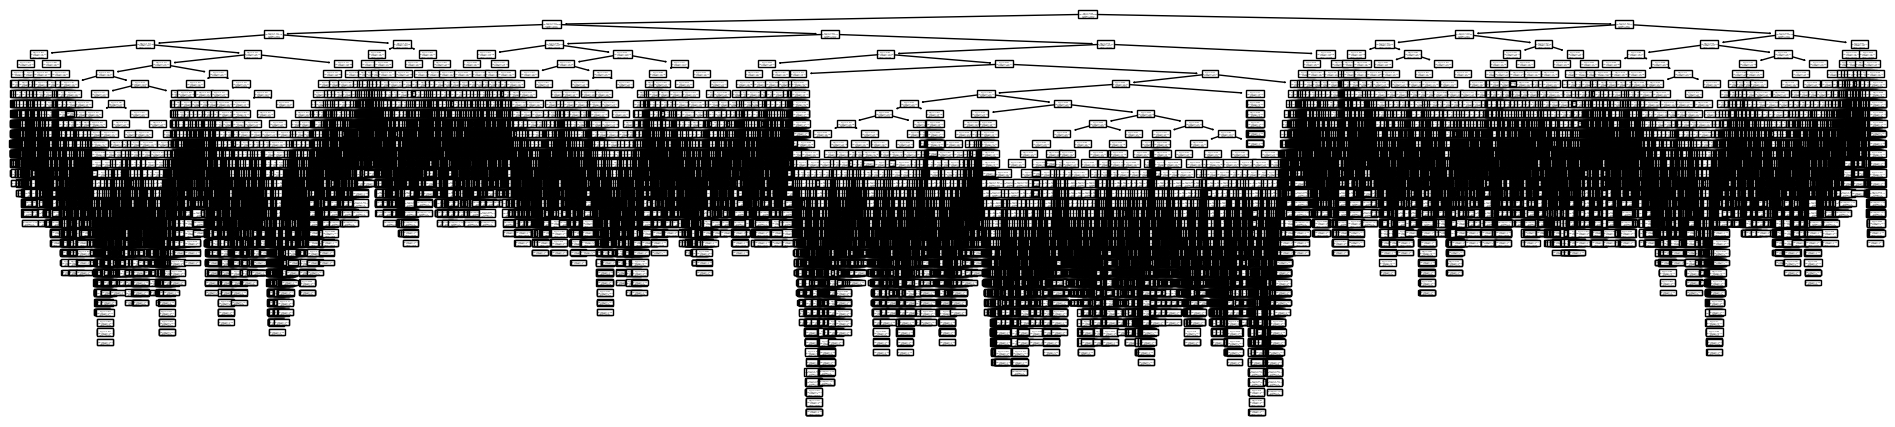

In [33]:
from sklearn import tree

clf = tree.DecisionTreeRegressor(random_state=42)
clf.fit(x_train_scaled, y_train_processed.iloc[:, 0])      

fig3 = plt.figure(figsize=(24, 18))
ax1 = plt.subplot2grid((3, 2), (0, 0), colspan=2)

tree.plot_tree(clf, ax=ax1)

plt.show()

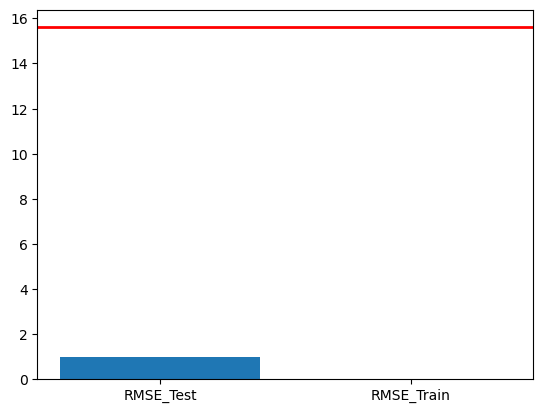

3.6134892147001034e-16


In [34]:
from sklearn.metrics import root_mean_squared_error

pred_test = clf.predict(x_test_scaled)       
pred_train = clf.predict(x_train_scaled)     

raw_rmse_test_tey = root_mean_squared_error(y_test_processed.iloc[:, 0], pred_test)
raw_rmse_train_tey = root_mean_squared_error(y_train_processed.iloc[:, 0], pred_train)

fig4 = plt.figure()
ax1 = fig4.add_subplot(1,1,1)

ax1.bar(["RMSE_Test", "RMSE_Train"], [raw_rmse_test_tey, raw_rmse_train_tey])
ax1.axhline(y=baseline_rmse.iloc[0, 1], color="red", linewidth=2, linestyle="-", label="RMSE_Baseline")

plt.show()
print(raw_rmse_train_tey)

In [35]:
importance = pd.DataFrame({
    "feature": features.columns,
    "importance": clf.feature_importances_
})

print(importance)

  feature  importance
0    year    0.003670
1      AT    0.018418
2      AP    0.000484
3      AH    0.000526
4    AFDP    0.000886
5    GTEP    0.616645
6     TIT    0.304872
7     TAT    0.054499


#### Auswertung:
> - bereits ohne optimierte Parameter deutlich bessere Vorhersageleistung im vgl. zum Baseline Model
> - hohe Feature Importance GTEP (Korrelation TEY GTEP, 0,96)

#### optimale Werte für max_depth, min_samples_leaf und ccp_alpha finden
> - Analyse von RMSE auf Trainings und Testdaten
> - Systematische manuelle Suche der Wertebereiche
> - erst großen Bereich betrachten, um lokale Minima zu identifizieren, dann Bereiche um diese genauer betrachten 
> - finden bester Werte durch Auswerten der Grafiken
> - Im folgenden ist nur der finale Bereich dokumentiert

lowest RMSE max_depth:
max_depth    16.000000
rmse          0.981951
Name: 10, dtype: float64
lowest RMSE min_samples_leaf:
min_samples_leaf    3.00000
rmse                0.94111
Name: 2, dtype: float64
lowest RMSE ccp_alpha:
ccp_alpha    0.000100
rmse         0.972098
Name: 2, dtype: float64


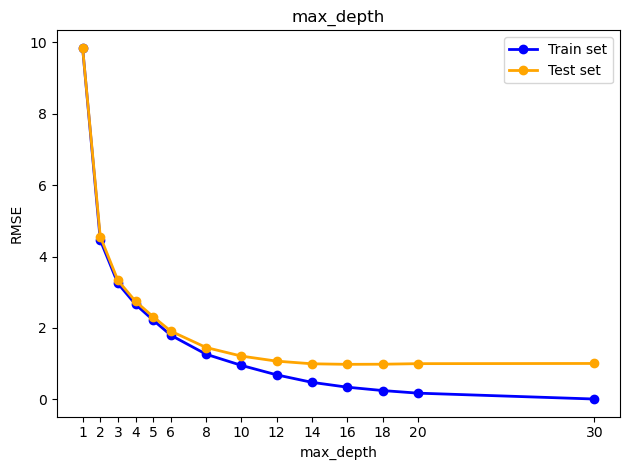

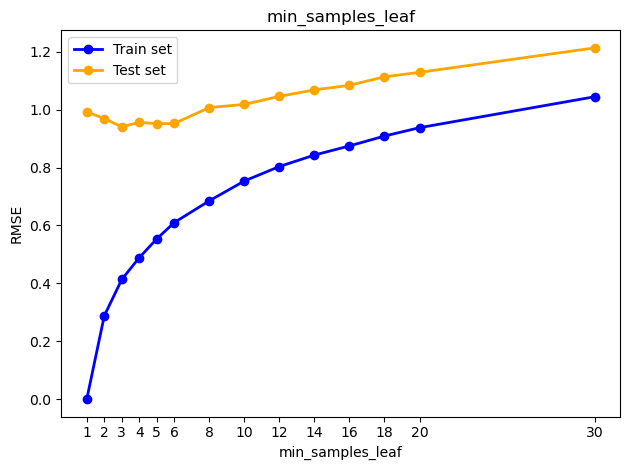

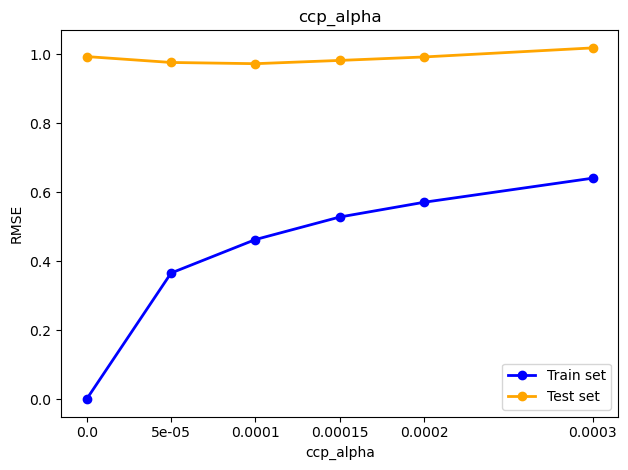

In [36]:
tey_params = {
        "max_depth": [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 30],
        "min_samples_leaf": [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 30],
        "ccp_alpha": [0.0, 0.00005, 0.0001, 0.00015, 0.0002, 0.0003]
    }

res = run_params_pipeline(x_train_scaled, y_train_processed.iloc[:, 0],
                          x_test_scaled, y_test_processed.iloc[:, 0],
                          tey_params,
                          baseline_rmse.iloc[0, 1],
                          "Tey (Energieertrag)")


#### Auswertung:
> - Max Depth:
>   - großer Einfluss auf Genauigkeit der Vorhersage bzw. RMSE
>   - ab ~20 RMSE test gleichbleibend, RMSE train fällt weiter -> Generalization gap steigt
>   - Finale Werte: [None, 14, 15, 16, 17, 18]
> - min_samples_leaf:
>   - klein -> starkes Overfitting
>   - groß -> Underfitting
>   - Finale Werte: [1, 2, 3, 4, 5]
> - ccp_alpha:
>   - vergleichsweise geringer Einfluss auf RMSE
>   - sehr kleiner Wertebereich
>   - großer Einfluss auf Trainingsvorhersage, kleiner Einfluss auf Testvorhersage
>   - sensibel gegenüber Trainingsdatenstruktur -> stabile Ergebnisse nur bei fixiertem random_state
>   - Finale Werte: [0.0(kein ccp),0.00005, 0.0001, 0.00015]
> - Default werte werden ebenfalls mit betrachtet

### Beste Parameterkandidaten finden
> - alle möglichen Kombinationen definierter Bereiche testen
> - Verwendung find_best_tree(), Vorgehen über Zelle 90 beschrieben

   ccp_alpha  max_depth  min_samples_leaf
0        0.0         18                 3


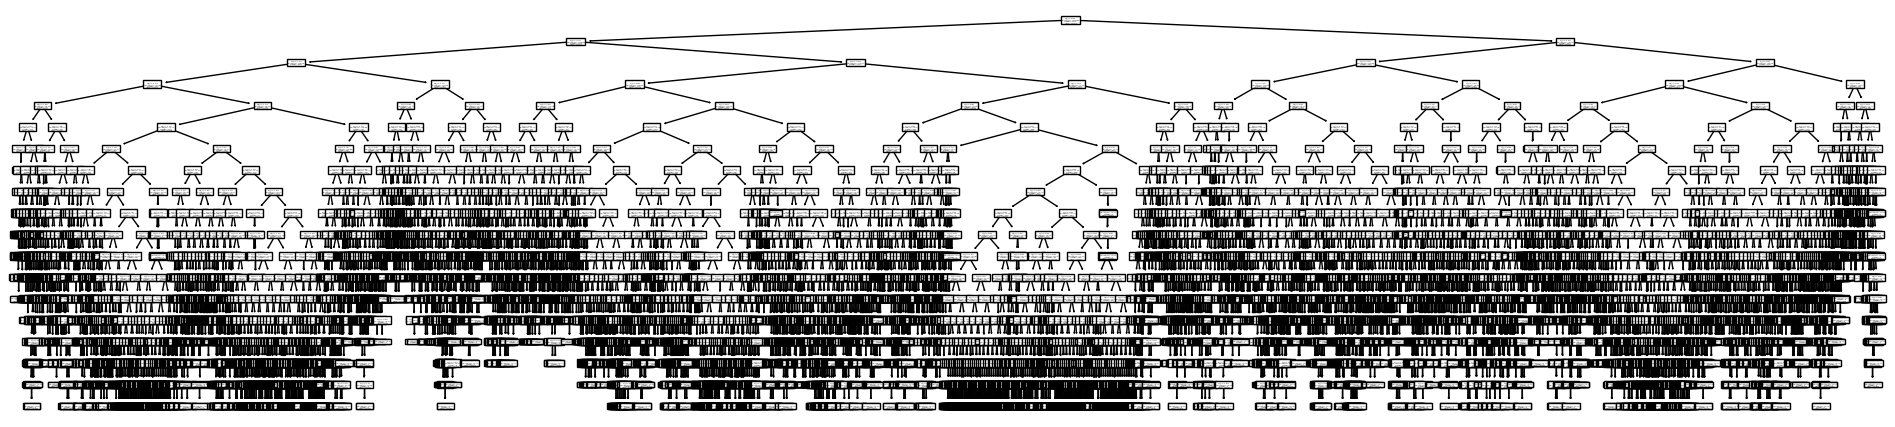

In [38]:
best_params = {
    "max_depth": [None, 14, 15, 16, 17, 18],
    "min_samples_leaf": [1, 2, 3, 4, 5],
    "ccp_alpha": [0.0,0.00005, 0.0001, 0.00015]
}

best_params_tey, best_tree_tey = find_best_tree(
    x_train_scaled,
    y_train_processed.iloc[:, 0],
    best_params,
)

print(best_params_tey)

fig = plt.figure(figsize=(24, 18))
ax1 = plt.subplot2grid((3, 2), (0, 0), colspan=2)

tree.plot_tree(best_tree_tey, ax=ax1)

plt.show()

## Vorhersage Kohlenmonoxid Emissionen (CO)

#### ohne Optimierung

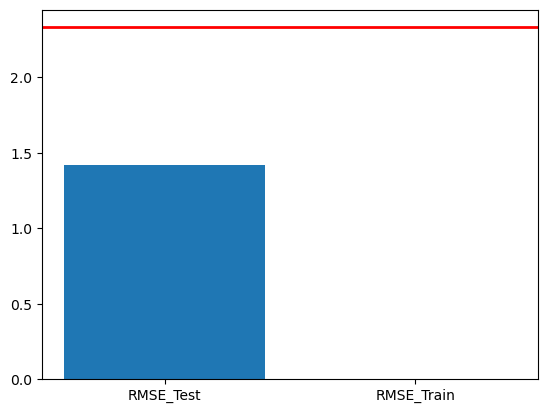

3.1728213082421197e-18


In [39]:
clf = tree.DecisionTreeRegressor(random_state=42)
clf.fit(x_train_scaled, y_train_processed.iloc[:, 1])  

pred_test = clf.predict(x_test_scaled)       
pred_train = clf.predict(x_train_scaled)     

raw_rmse_test_co = root_mean_squared_error(y_test_processed.iloc[:, 1], pred_test)
raw_rmse_train_co = root_mean_squared_error(y_train_processed.iloc[:, 1], pred_train)

fig4 = plt.figure()
ax1 = fig4.add_subplot(1,1,1)

ax1.bar(["RMSE_Test", "RMSE_Train"], [raw_rmse_test_co, raw_rmse_train_co])
ax1.axhline(y=baseline_rmse.iloc[1, 1], color="red", linewidth=2, linestyle="-", label="RMSE_Baseline")

plt.show()
print(raw_rmse_train_co)

#### Auswertung:
> - auch hier ohne ohne Hyperparameter Optimierung sehr gute Prediction im vgl. zum Baseline Model
> - sehr niedriger RMSE auf Trainingsdaten -> Zeichen für Overfitting

#### optimale Werte für max_depth, min_samples_leaf und ccp_alpha finden
> - Analyse von RMSE auf Trainings und Testdaten
> - Systematische manuelle Suche der Wertebereiche
> - erst großen Bereich betrachten, um lokale Minima zu identifizieren, dann Bereiche um diese genauer betrachten 
> - finden bester Werte durch Auswerten der Grafiken
> - Im folgenden ist nur der finale Bereich dokumentiert

lowest RMSE max_depth:
max_depth    4.000000
rmse         1.301538
Name: 3, dtype: float64
lowest RMSE min_samples_leaf:
min_samples_leaf    17.000000
rmse                 1.176539
Name: 8, dtype: float64
lowest RMSE ccp_alpha:
ccp_alpha    0.000350
rmse         1.339048
Name: 4, dtype: float64


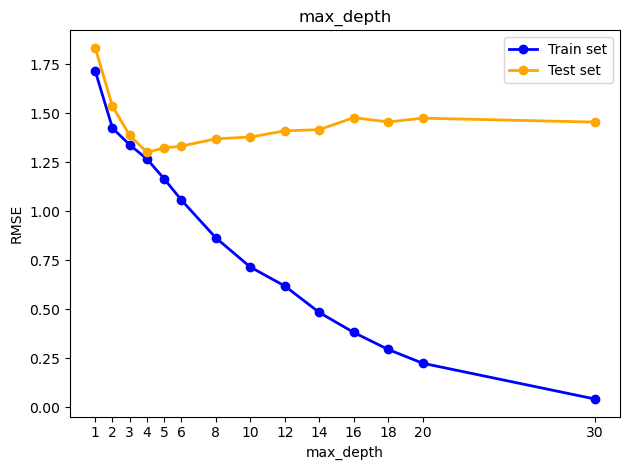

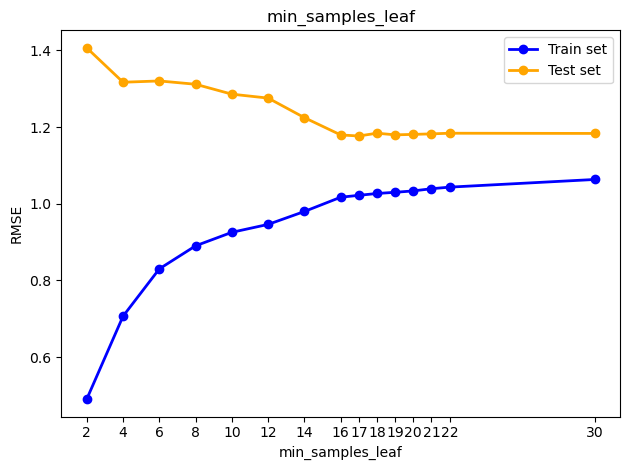

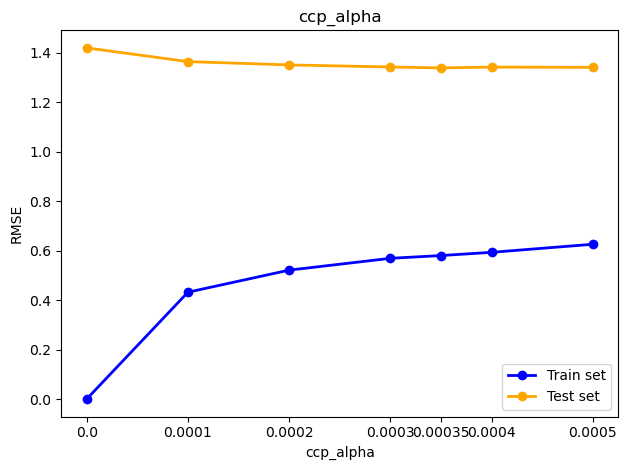

In [40]:
co_params = {
        "max_depth": [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 30],
        "min_samples_leaf": [2, 4, 6, 8, 10, 12, 14, 16, 17, 18, 19, 20, 21, 22, 30],
        "ccp_alpha": [0.0, 0.0001, 0.0002, 0.0003, 0.00035, 0.0004, 0.0005]
    }

res = run_params_pipeline(x_train_scaled, y_train_processed.iloc[:, 1],
                          x_test_scaled, y_test_processed.iloc[:, 1],
                          co_params,
                          baseline_rmse.iloc[1, 1],
                          "CO (Kohlenmonoxid Emissionen)")


#### Auswertung:
> - Max Depth:
>   - ab ~20 RMSE test gleichbleibend, RMSE train fällt weiter -> zunehmender Generalization Gap
>   - Finale Werte: [None, 3, 4, 5, 6, 7]
> - min_samples_leaf:
>   - klein -> starkes overfitting
>   - groß -> underfitting
>   - Finale Werte: [1, 15, 16, 17, 18, 19]
> - ccp_alpha:
>   - vergleichsweise geringer Einfluss auf RMSE
>   - großer Einfluss auf Trainprediction, kleiner Einfluss auf Testprediction
>   - stark abhängig von Trainingsdaten
>   - Finale Werte: [0.0, 0.0003, 0.000325, 0.00035, 0.000375, 0.0004]
> - Default werte werden ebenfalls mit betrachtet

### Beste Parameterkandidaten finden
> - alle möglichen Kombinationen definierter Bereiche testen
> - Verwendung find_best_tree(), Vorgehen über Zelle 90 beschrieben

In [41]:
best_params = {
    "max_depth": [None, 3, 4, 5, 6, 7],
    "min_samples_leaf": [1, 15, 16, 17, 18, 19],
    "ccp_alpha": [0.0, 0.0003, 0.000325, 0.00035, 0.000375, 0.0004]
}

best_params_co, best_tree_co = find_best_tree(
    x_train_scaled,
    y_train_processed.iloc[:, 1],
    best_params,
)

print(best_params_co)

   ccp_alpha max_depth  min_samples_leaf
0     0.0003      None                17


## Vorhersage Stickoxid Emissionen (NOX)

#### ohne Optimierung

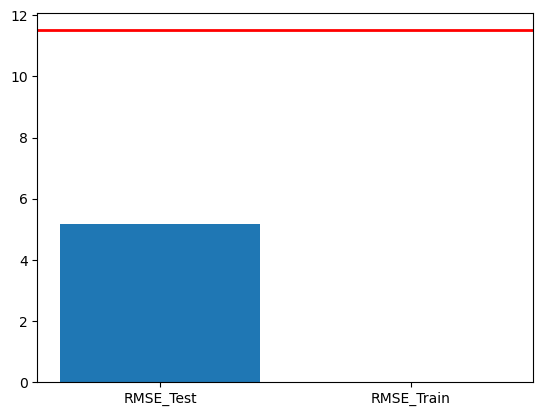

0.0


In [42]:
clf = tree.DecisionTreeRegressor(random_state=42)
clf.fit(x_train_scaled, y_train_processed.iloc[:, 2])  

pred_test = clf.predict(x_test_scaled)       
pred_train = clf.predict(x_train_scaled)     

raw_rmse_test_nox = root_mean_squared_error(y_test_processed.iloc[:, 2], pred_test)
raw_rmse_train_nox = root_mean_squared_error(y_train_processed.iloc[:, 2], pred_train)

fig4 = plt.figure()
ax1 = fig4.add_subplot(1,1,1)

ax1.bar(["RMSE_Test", "RMSE_Train"], [raw_rmse_test_nox, raw_rmse_train_nox])
ax1.axhline(y=baseline_rmse.iloc[2, 1], color="red", linewidth=2, linestyle="-", label="RMSE_Baseline")

plt.show()
print(raw_rmse_train_nox)

#### Auswertung:
> - auch hier ohne optimierte Parameter sehr gute Prediction im vgl. zum Baseline Model
> - RMSE auf Trainingsdaten bei 0.0 -> Modell hat Trainingsdaten „auswendig gelernt“
> - höchster Fehler ohne Optimierung im Vergleich zu anderen skalierten Targets

#### optimale Werte für max_depth, min_samples_leaf und ccp_alpha finden
> - Analyse von RMSE auf Trainings und Testdaten
> - Systematische manuelle Suche der Wertebereiche
> - erst großen Bereich betrachten, um lokale Minima zu identifizieren, dann Bereiche um diese genauer betrachten 
> - finden bester Werte durch Auswerten der Grafiken
> - Im folgenden ist nur der finale Bereich dokumentiert

lowest RMSE max_depth:
max_depth    10.000000
rmse          4.786927
Name: 7, dtype: float64
lowest RMSE min_samples_leaf:
min_samples_leaf    6.000000
rmse                4.564877
Name: 3, dtype: float64
lowest RMSE ccp_alpha:
ccp_alpha    0.003750
rmse         4.822394
Name: 3, dtype: float64


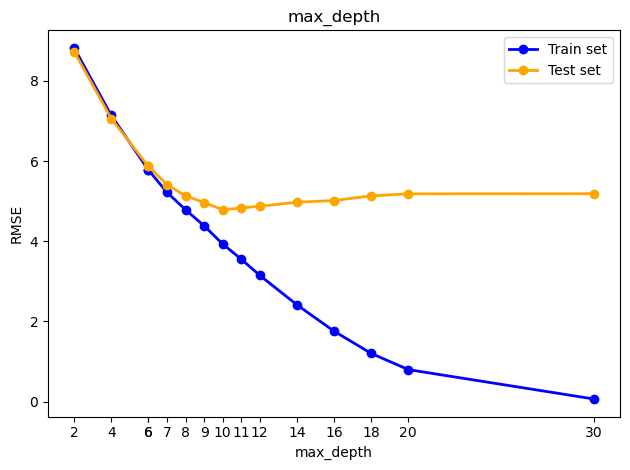

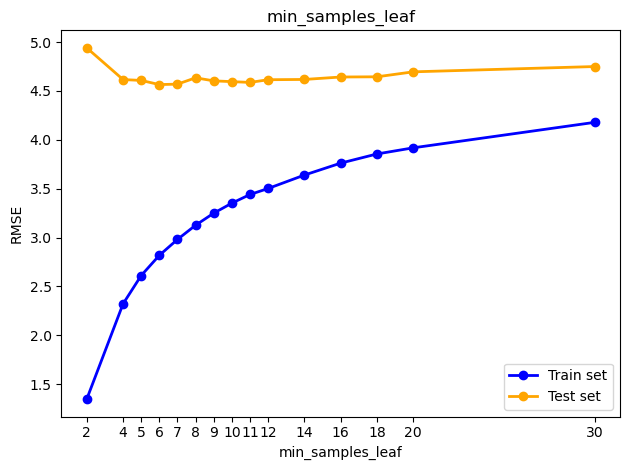

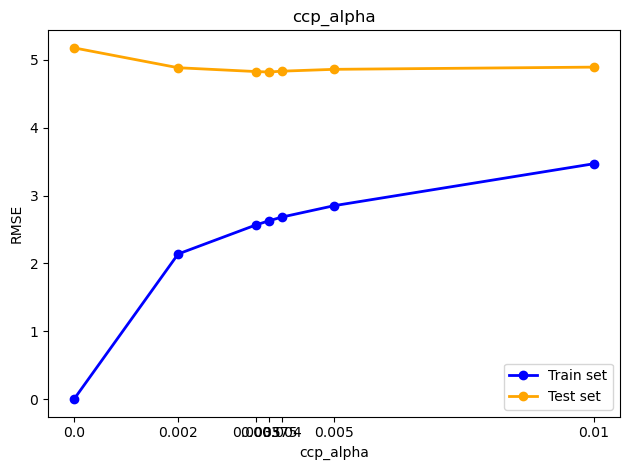

In [43]:
nox_params = {
        "max_depth": [2, 4, 6, 6, 7, 8, 9, 10, 11, 12, 14, 16, 18, 20, 30],
        "min_samples_leaf": [2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 18, 20, 30],
        "ccp_alpha": [0.0, 0.002, 0.0035, 0.00375, 0.004, 0.005, 0.01]
    }

res = run_params_pipeline(x_train_scaled, y_train_processed.iloc[:, 2],
                          x_test_scaled, y_test_processed.iloc[:, 2],
                          nox_params,
                          baseline_rmse.iloc[2, 1],
                          "NOX (Stickoxid Emissionen)")


#### Auswertung:
> - Max Depth:
>   - Finale Werte: [None, 8, 9, 10, 11, 12]
> - min_samples_leaf:
>   - Finale Werte: [1, 5, 6, 7, 9, 10, 11]
> - ccp_alpha:
>   - Deutlich höhere Werte als bei anderen Zielvariablen (TEY, CO)
>   - Finale Werte: [0.0, 0.002, 0.0035, 0.00375, 0.004, 0.005]
> - Default werte werden ebenfalls mit betrachtet

### Beste Parameterkandidaten finden
> - alle möglichen Kombinationen definierter Bereiche testen
> - Verwendung find_best_tree(), Vorgehen über Zelle 90 beschrieben

In [44]:
best_params = {
    "max_depth": [None, 8, 9, 10, 11, 12],
    "min_samples_leaf": [1, 5, 6, 7, 9, 10, 11],
    "ccp_alpha": [0.0, 0.002, 0.0035, 0.00375, 0.004, 0.005]
}

best_params_nox, best_tree_nox = find_best_tree(
    x_train_scaled,
    y_train_processed.iloc[:, 2],
    best_params,
)

print(best_params_nox)

   ccp_alpha max_depth  min_samples_leaf
0        0.0      None                10


In [ ]:
pred_test_tey = best_tree_tey.predict(x_test_scaled)
pred_train_tey = best_tree_tey.predict(x_train_scaled)

pred_test_co = best_tree_co.predict(x_test_scaled)
pred_train_co = best_tree_co.predict(x_train_scaled)

pred_test_nox = best_tree_nox.predict(x_test_scaled)
pred_train_nox = best_tree_nox.predict(x_train_scaled)

rmse_test_tey = root_mean_squared_error(y_test_processed.iloc[:, 0], pred_test_tey)
rmse_train_tey = root_mean_squared_error(y_train_processed.iloc[:, 0], pred_train_tey)

rmse_test_co = root_mean_squared_error(y_test_processed.iloc[:, 1], pred_test_co)
rmse_train_co = root_mean_squared_error(y_train_processed.iloc[:, 1], pred_train_co)

rmse_test_nox = root_mean_squared_error(y_test_processed.iloc[:, 2], pred_test_nox)
rmse_train_nox = root_mean_squared_error(y_train_processed.iloc[:, 2], pred_train_nox)

## Zusammenfassung

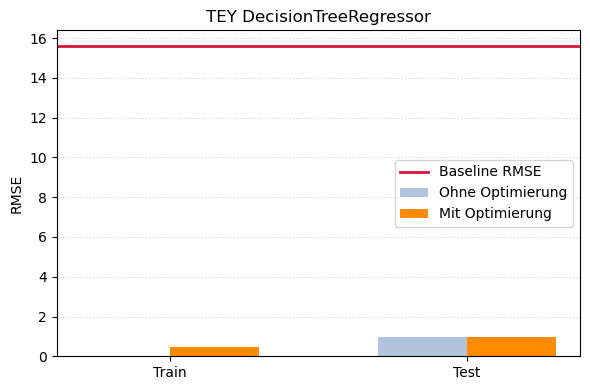

In [46]:
#tey
fig, ax = plt.subplots(figsize=(6,4))

ax.bar(np.arange(2) - 0.15,
       [raw_rmse_train_tey, raw_rmse_test_tey],
       width=0.3,
       label="Ohne Optimierung",
       color="lightsteelblue")

ax.bar(np.arange(2) + 0.15,
       [rmse_train_tey, rmse_test_tey],
       width=0.3,
       label="Mit Optimierung",
       color="darkorange")

ax.axhline(baseline_rmse.iloc[0, 1], color="crimson", linewidth=2, label="Baseline RMSE")

ax.set_xticks(np.arange(2))
ax.set_xticklabels(["Train", "Test"])
ax.set_ylabel("RMSE")
ax.set_title("TEY DecisionTreeRegressor")
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

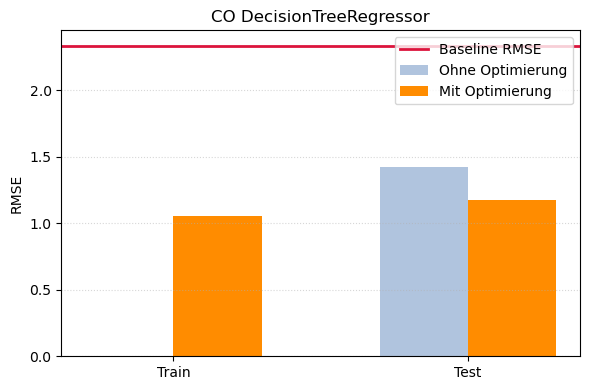

In [47]:
#co
fig, ax = plt.subplots(figsize=(6,4))

ax.bar(np.arange(2) - 0.15,
       [raw_rmse_train_co, raw_rmse_test_co],
       width=0.3,
       label="Ohne Optimierung",
       color="lightsteelblue")

ax.bar(np.arange(2) + 0.15,
       [rmse_train_co, rmse_test_co],
       width=0.3,
       label="Mit Optimierung",
       color="darkorange")

ax.axhline(baseline_rmse.iloc[1, 1], color="crimson", linewidth=2, label="Baseline RMSE")

ax.set_xticks(np.arange(2))
ax.set_xticklabels(["Train", "Test"])
ax.set_ylabel("RMSE")
ax.set_title("CO DecisionTreeRegressor")
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

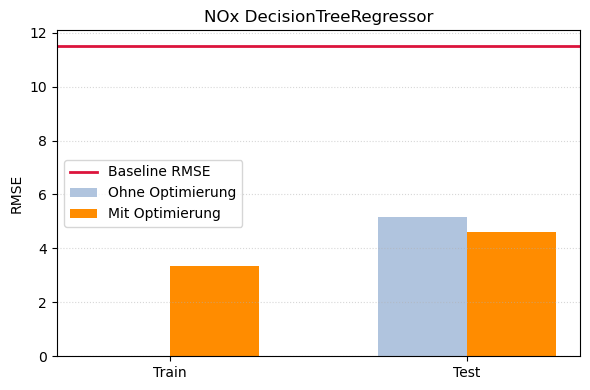

In [48]:
#nox
fig, ax = plt.subplots(figsize=(6,4))

ax.bar(np.arange(2) - 0.15,
       [raw_rmse_train_nox, raw_rmse_test_nox],
       width=0.3,
       label="Ohne Optimierung",
       color="lightsteelblue")

ax.bar(np.arange(2) + 0.15,
       [rmse_train_nox, rmse_test_nox],
       width=0.3,
       label="Mit Optimierung",
       color="darkorange")

ax.axhline(baseline_rmse.iloc[2, 1], color="crimson", linewidth=2, label="Baseline RMSE")

ax.set_xticks(np.arange(2))
ax.set_xticklabels(["Train", "Test"])
ax.set_ylabel("RMSE")
ax.set_title("NOx DecisionTreeRegressor")
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

## Zusammenfassung DecisionTreeRegressor (CART)
> - gut modellierbarer Datensatz, viele stark mit Targets korrelierende Features, geringer Anteil an Ausreißern
> - Bereits ohne Optimierung RMSE deutlich unter Baseline Prediction
> - Auf Trainingsdaten ohne Optimierung Fehler nahe 0 -> starkes Overfitting
> - Nach Optimierung Train und Test RMSE angenähert
> - Durch Optimierung wurden teilweise Parameter auf Default Werte gesetzt z. B. bei CO (max_depth) oder NOx (ccp_alpha und max_depth)
> -> Vorgehen nicht Optimal, besser wäre Prüfung aller möglichen Parameterkombinationen, ccp_alpha float -> Abschätzung
> - Stärkste Optimierung bei CO
> - insgesamt geringer Einfluss von Optimierung auf RMSE
> - niedrigster RMSE bei TEY durch starke Korrelation mit Feature GTEP

# Single Output NN

In [50]:
import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

## Architekturwahl

In [51]:
def build_model(units_list, input_shape):
    model = keras.Sequential([
        keras.Input(shape=(input_shape,)),
        layers.Dense(units_list[0], activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(units_list[1], activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(units_list[2], activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model

configs = [
    {'name': 'Small',   'units': [64, 32, 16],   'epochs': 200, 'patience': 15},
    {'name': 'Medium',  'units': [128, 64, 32],  'epochs': 200, 'patience': 15},
    {'name': 'Large',   'units': [256, 128, 64], 'epochs': 200, 'patience': 30},
    {'name': 'XLarge',  'units': [512, 256, 128], 'epochs': 300, 'patience': 75},
]

In [52]:
results = []
for config in configs:
    print(f"Training {config['name']}...")
    model = build_model(config['units'], x_train_scaled.shape[1])
    
    early_stop = EarlyStopping(monitor='val_loss', patience=config['patience'], restore_best_weights=True)
    
    start_time = time.time()
    
    history = model.fit(x_train_scaled, y_train_processed.iloc[:,0],
                        validation_split=0.2, 
                        epochs=config['epochs'], 
                        batch_size=256,
                        callbacks=[early_stop], 
                        verbose=0)
    
    elapsed_time = time.time() - start_time
    
    y_pred = model.predict(x_test_scaled, verbose=0)
    rmse = np.sqrt(mean_squared_error(y_test_processed.iloc[:,0], y_pred))
    
    results.append({
        'Architektur': config['name'], 
        'Test RMSE': round(rmse, 4),
        'Epochs': len(history.history['loss']),
        'Zeit (s)': round(elapsed_time, 2)
    })

df_results = pd.DataFrame(results)
print("\nArchitektur Vergleich für TEY")
print(df_results.to_string(index=False))

baseline_tey = baseline_rmse.loc[baseline_rmse['target'] == 'TEY', 'rmse'].values[0]

Training Small...
Training Medium...
Training Large...
Training XLarge...

Architektur Vergleich für TEY
Architektur  Test RMSE  Epochs  Zeit (s)
      Small     1.1353      55     83.27
     Medium     0.6595      98    141.70
      Large     0.6110      92    133.34
     XLarge     0.4761     300    444.79


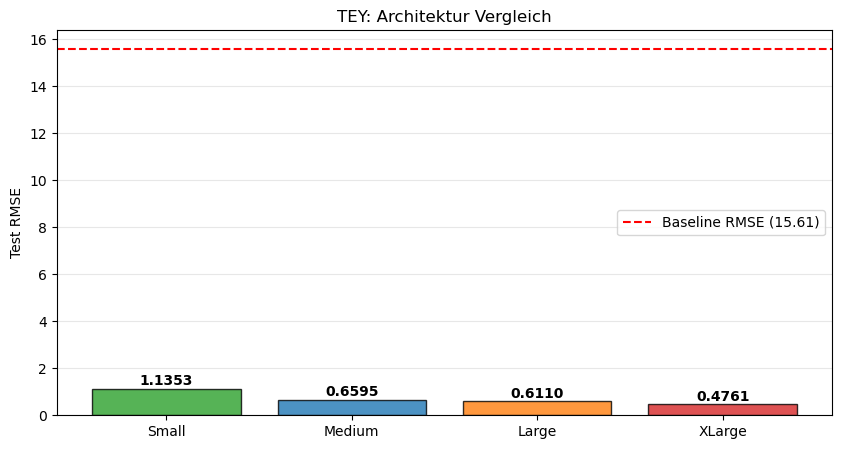

In [53]:
plt.figure(figsize=(10, 5))
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']
bars = plt.bar(df_results['Architektur'], df_results['Test RMSE'], color=colors, alpha=0.8, edgecolor='black')

for bar, rmse in zip(bars, df_results['Test RMSE']):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02, f'{rmse:.4f}', ha='center', va='bottom', fontweight='bold')

plt.axhline(y=baseline_tey, color='red', linestyle='--', linewidth=1.5, label=f'Baseline RMSE ({baseline_tey:.2f})')
plt.ylabel('Test RMSE')
plt.title('TEY: Architektur Vergleich')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.show()

In [54]:
small  = df_results[df_results['Architektur'] == 'Small'].iloc[0]
medium = df_results[df_results['Architektur'] == 'Medium'].iloc[0]
large  = df_results[df_results['Architektur'] == 'Large'].iloc[0]
xlarge = df_results[df_results['Architektur'] == 'XLarge'].iloc[0]

rmse_improvement_vs_small = (small['Test RMSE']  - medium['Test RMSE']) / small['Test RMSE']  * 100
rmse_gap_vs_large         = (medium['Test RMSE'] - large['Test RMSE'])  / large['Test RMSE']  * 100
time_ratio_large          = large['Zeit (s)']  / medium['Zeit (s)']
time_ratio_xlarge         = xlarge['Zeit (s)'] / medium['Zeit (s)']

print(f"Medium ist {rmse_improvement_vs_small:.1f}% besser als Small  (RMSE: {small['Test RMSE']:.4f} => {medium['Test RMSE']:.4f})")
print(f"Medium ist {rmse_gap_vs_large:.1f}% schlechter als Large  (RMSE: {medium['Test RMSE']:.4f} => {large['Test RMSE']:.4f})")
print()
print(f"Trainingszeit:  Large {time_ratio_large:.1f}x länger als Medium  |  XLarge {time_ratio_xlarge:.1f}x länger als Medium")
print(f"Epochen:        Medium {medium['Epochs']}  |  Large {large['Epochs']}  |  XLarge {xlarge['Epochs']}")

Medium ist 41.9% besser als Small  (RMSE: 1.1353 => 0.6595)
Medium ist 7.9% schlechter als Large  (RMSE: 0.6595 => 0.6110)

Trainingszeit:  Large 0.9x länger als Medium  |  XLarge 3.1x länger als Medium
Epochen:        Medium 98  |  Large 92  |  XLarge 300


# Begründung der NN Architektur

Der Architekturvergleich **Small** vs. **Medium** vs. **Large** vs. **XLarge** wurde auf TEY durchgeführt,
da TEY die stärkste Korrelation mit den Features aufweist und sich daher am besten
eignet, um Unterschiede zwischen Architekturen sauber sichtbar zu machen.

**Medium (128-64-32) wurde als finale Architektur gewählt**, weil sie den besten
Trade-off zwischen Vorhersagegenauigkeit und Trainingsaufwand bietet:

- Gegenüber Small bessere RMSE bei überschaubarer Größenzunahme
- Schlechtere RMSE gegenüber Large , aber deutlich weniger Epochen
  bis zur Konvergenz
- Large und XLarge erzielen keine proportional besseren Ergebnisse im Verhältnis
  zur längeren Trainingszeit

BatchNormalization und Dropout (0.2) sorgen in allen Schichten für stabiles Training
und ausreichende Regularisierung.

Diese Architektur wird anschließend einheitlich für alle Targets (TEY, CO, NOX)
sowie für die Multi Output Modelle verwendet, um die Vergleichbarkeit zu gewährleisten.

## TEY (Energieertrag) Single Output NN

### TEY NN mit Skalierung

In [55]:
model_tey_scaled = keras.Sequential([
    keras.Input(shape=(x_train_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)  # Single Output
])

model_tey_scaled.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

start_time_model_tey_scaled = time.time()

# Training
history_tey_scaled = model_tey_scaled.fit(
    x_train_scaled, y_train_processed.iloc[:, 0], # TEY
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

elapsed_time_model_tey_scaled = time.time() - start_time_model_tey_scaled

# Evaluierung auf Testdaten
y_pred_tey_scaled = model_tey_scaled.predict(x_test_scaled, verbose=0).flatten()
rmse_tey_scaled = np.sqrt(mean_squared_error(y_test_processed.iloc[:, 0], y_pred_tey_scaled))
mae_tey_scaled = mean_absolute_error(y_test_processed.iloc[:, 0], y_pred_tey_scaled)
r2_tey_scaled = r2_score(y_test_processed.iloc[:, 0], y_pred_tey_scaled)


print(f"Scaled Data - TEY Results:")
print(f"  RMSE: {rmse_tey_scaled:.6f}")
print(f"  MAE:  {mae_tey_scaled:.6f}")
print(f"  R²:   {r2_tey_scaled:.6f}")
print(f"  Zeit: {round(elapsed_time_model_tey_scaled, 2)} Sekunden")

Scaled Data - TEY Results:
  RMSE: 1.429886
  MAE:  1.079018
  R²:   0.991611
  Zeit: 57.87 Sekunden


In [56]:
print("Mittelwert von TEY:", round(y_train_processed["TEY"].mean(), 5))
print("Standardabweichung von TEY:", round(y_train_processed["TEY"].std(), 5))

Mittelwert von TEY: 133.47942
Standardabweichung von TEY: 15.62038


### Interpretation  
**RMSE** beschreibt den typischen Vorhersagefehler in Einheiten der Zielgröße.  
- Die Standardabweichung von TEY liegt bei ca. 15, der Mittelwert bei ca. 133  
- Ein niedriger RMSE relativ zur Standardabweichung zeigt, dass das Modell die Varianz der Daten gut erklärt  
- Als Prozentsatz des Mittelwerts ergibt sich ein sehr kleiner relativer Fehler  
=> Das Modell trifft TEY sehr präzise

**MAE** ist der durchschnittliche absolute Fehler (robuster gegenüber Ausreißern als RMSE).  
- Im Schnitt liegt jede Vorhersage nur wenige TEY Einheiten daneben  
=> Keine systematischen Ausreißfehler, gleichmäßig gutes Lernverhalten

**R²** gibt an, wie viel der Varianz der Zielvariable erklärt wird.  
- Ein Wert nahe 1.0 bedeutet, das Modell erklärt nahezu die gesamten Schwankungen in TEY  
=> Sehr gute Vorhersagequalität

### TEY NN Ohne Skalierung (raw)

In [57]:
model_tey_raw = keras.Sequential([
    keras.Input(shape=(x_train_raw.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)  # Single Output
])

model_tey_raw.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

start_time_model_tey_raw = time.time()

history_tey_raw = model_tey_raw.fit(
    x_train_raw, y_train_raw.iloc[:, 0], # TEY
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=0
)

elapsed_time_model_tey_raw = time.time() - start_time_model_tey_raw

y_pred_tey_raw = model_tey_raw.predict(x_test_raw, verbose=0).flatten()
rmse_tey_raw = np.sqrt(mean_squared_error(y_test_raw.iloc[:, 0], y_pred_tey_raw))
mae_tey_raw = mean_absolute_error(y_test_raw.iloc[:,0], y_pred_tey_raw)
r2_tey_raw = r2_score(y_test_raw.iloc[:,0], y_pred_tey_raw)

print(f"Raw Data - TEY Results:")
print(f"  RMSE: {rmse_tey_raw:.6f}")
print(f"  MAE:  {mae_tey_raw:.6f}")
print(f"  R²:   {r2_tey_raw:.6f}")
print(f"  Zeit: {round(elapsed_time_model_tey_raw, 2)} Sekunden")

Raw Data - TEY Results:
  RMSE: 23.610162
  MAE:  19.840386
  R²:   -1.287315
  Zeit: 14.51 Sekunden


### Interpretation
**RMSE:** Der typische Vorhersagefehler liegt deutlich über der Standardabweichung der Daten
   => das Modell ist schlechter als eine naive Mittelwertvorhersage.

**MAE:** Im Schnitt liegt die Vorhersage weit neben dem tatsächlichen Wert.

Ein negativer **R²** Wert bedeutet: ohne Feature Scaling ist das neuronale Netz nicht in der Lage, die unterschiedlichen Größenordnungen der Eingabefeatures korrekt zu verarbeiten. Große Featurewerte dominieren die Gradientenberechnung und das Training destabilisiert sich.

- Baseline (Mittelwert immer vorhersagen): Fehler ca. = Standardabweichung von TEY (~15)
- Dieses Modell: ca. doppelt so hoher Fehler

=> Feature Scaling ist für neuronale Netze ohne BatchNormalization zwingend erforderlich.

### TEY NN mit BatchNormalization()

In [58]:
model_tey_batch = keras.Sequential([
    keras.Input(shape=(x_train_raw.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1)  # Single Output
])

model_tey_batch.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

start_time_model_tey_batch = time.time()

# Training
history_tey_batch = model_tey_batch.fit(
    x_train_raw, y_train_raw.iloc[:, 0], # TEY
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

elapsed_time_model_tey_batch = time.time() - start_time_model_tey_batch

# Evaluierung auf Testdaten
y_pred_tey_batch = model_tey_batch.predict(x_test_raw, verbose=0).flatten()
rmse_tey_batch = np.sqrt(mean_squared_error(y_test_raw.iloc[:, 0], y_pred_tey_batch))
mae_tey_batch = mean_absolute_error(y_test_raw.iloc[:, 0], y_pred_tey_batch)
r2_tey_batch = r2_score(y_test_raw.iloc[:, 0], y_pred_tey_batch)

print(f"Raw + Batch Norm - TEY Results:")
print(f"  RMSE: {rmse_tey_batch:.6f}")
print(f"  MAE:  {mae_tey_batch:.6f}")
print(f"  R²:   {r2_tey_batch:.6f}")
print(f"  Zeit: {round(elapsed_time_model_tey_batch, 2)} Sekunden")

Raw + Batch Norm - TEY Results:
  RMSE: 11.681858
  MAE:  10.499793
  R²:   0.440046
  Zeit: 32.16 Sekunden


### TEY NN mit Skalierung und BatchNormalization()

In [59]:
model_tey_scaled_batch = keras.Sequential([
    keras.Input(shape=(x_train_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1)  # Single Output
])

model_tey_scaled_batch.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

start_time_model_tey_scaled_batch = time.time()

# Training
history_tey_scaled_batch = model_tey_scaled_batch.fit(
    x_train_scaled, y_train_processed.iloc[:, 0], # TEY
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

elapsed_time_model_tey_scaled_batch = time.time() - start_time_model_tey_scaled_batch

# Evaluierung auf Testdaten
y_pred_tey_scaled_batch = model_tey_scaled_batch.predict(x_test_scaled, verbose=0).flatten()
rmse_tey_scaled_batch = np.sqrt(mean_squared_error(y_test_processed.iloc[:, 0], y_pred_tey_scaled_batch))
mae_tey_scaled_batch = mean_absolute_error(y_test_processed.iloc[:, 0], y_pred_tey_scaled_batch)
r2_tey_scaled_batch = r2_score(y_test_processed.iloc[:, 0], y_pred_tey_scaled_batch)


print(f"Scaled + Batch Data - TEY Results:")
print(f"  RMSE: {rmse_tey_scaled_batch:.6f}")
print(f"  MAE:  {mae_tey_scaled_batch:.6f}")
print(f"  R²:   {r2_tey_scaled_batch:.6f}")
print(f"  Zeit: {round(elapsed_time_model_tey_scaled_batch, 2)} Sekunden")

Scaled + Batch Data - TEY Results:
  RMSE: 0.651859
  MAE:  0.470035
  R²:   0.998256
  Zeit: 147.59 Sekunden


## Vergleich der verschiedenen Methoden

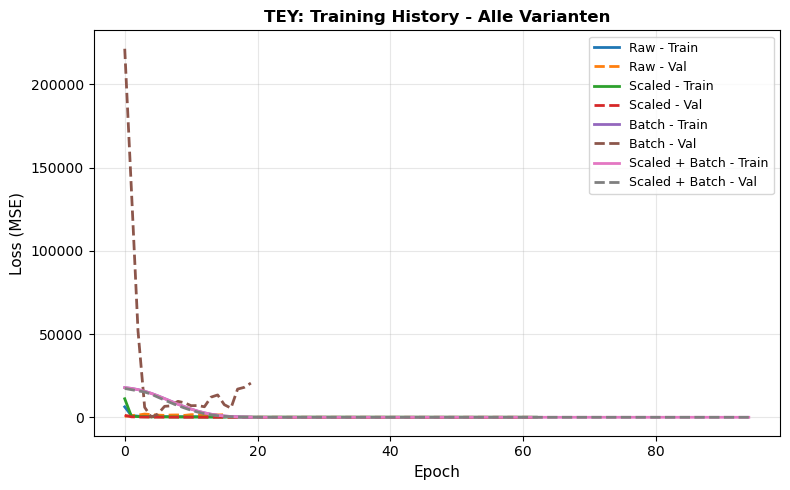

In [70]:
plt.figure(figsize=(8, 5))

# Loss Vergleich
plt.plot(history_tey_raw.history['loss'], label='Raw - Train', linewidth=2)
plt.plot(history_tey_raw.history['val_loss'], label='Raw - Val', linestyle='--', linewidth=2)
plt.plot(history_tey_scaled.history['loss'], label='Scaled - Train', linewidth=2)
plt.plot(history_tey_scaled.history['val_loss'], label='Scaled - Val', linestyle='--', linewidth=2)
plt.plot(history_tey_batch.history['loss'], label='Batch - Train', linewidth=2)
plt.plot(history_tey_batch.history['val_loss'], label='Batch - Val', linestyle='--', linewidth=2)
plt.plot(history_tey_scaled_batch.history['loss'], label='Scaled + Batch - Train', linewidth=2)
plt.plot(history_tey_scaled_batch.history['val_loss'], label='Scaled + Batch - Val', linestyle='--', linewidth=2)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss (MSE)', fontsize=11)
plt.title('TEY: Training History - Alle Varianten', fontsize=12, fontweight='bold')
plt.legend(fontsize=9)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

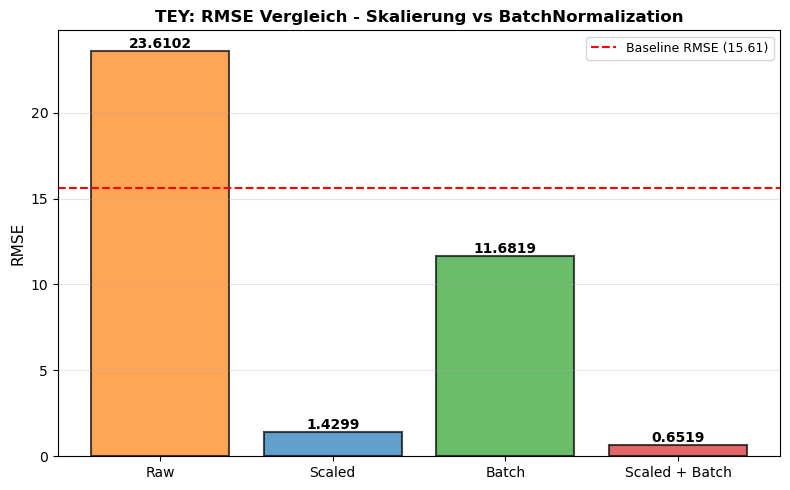

In [71]:
# RMSE Vergleich
plt.figure(figsize=(8, 5))

models = ['Raw', 'Scaled', 'Batch', 'Scaled + Batch']
rmse_values = [rmse_tey_raw, rmse_tey_scaled, rmse_tey_batch, rmse_tey_scaled_batch]
colors = ['#ff7f0e', '#1f77b4', '#2ca02c', '#d62728']
bars = plt.bar(models, rmse_values, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)
plt.ylabel('RMSE', fontsize=11)
plt.title('TEY: RMSE Vergleich - Skalierung vs BatchNormalization', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')

# Werte auf den Balken
for bar, rmse in zip(bars, rmse_values):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
                f'{rmse:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.axhline(
    y=baseline_rmse.loc[baseline_rmse['target'] == 'TEY', 'rmse'].values[0],
    color='red', linestyle='--', linewidth=1.5, label=f'Baseline RMSE ({baseline_rmse.loc[baseline_rmse["target"] == "TEY", "rmse"].values[0]:.2f})'
)
plt.legend(fontsize=9)

plt.tight_layout()
plt.show()

## CO (Kohlenmonoxid Emissionen) Single Output NN

### CO NN mit Skalierung und BatchNormalization()

In [72]:
model_co_scaled_batch = keras.Sequential([
    keras.Input(shape=(x_train_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1)  # Single Output
])

model_co_scaled_batch.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

start_time_model_co_scaled_batch = time.time()

# Training
history_co_scaled_batch = model_co_scaled_batch.fit(
    x_train_scaled, y_train_processed.iloc[:, 1], # CO
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)
elapsed_time_model_co_scaled_batch = time.time() - start_time_model_co_scaled_batch

# Evaluierung auf Testdaten
y_pred_co_scaled_batch = model_co_scaled_batch.predict(x_test_scaled, verbose=0).flatten()
rmse_co_scaled_batch = np.sqrt(mean_squared_error(y_test_processed.iloc[:, 1], y_pred_co_scaled_batch))
mae_co_scaled_batch = mean_absolute_error(y_test_processed.iloc[:, 1], y_pred_co_scaled_batch)
r2_co_scaled_batch = r2_score(y_test_processed.iloc[:, 1], y_pred_co_scaled_batch)

print(f"Scaled + Batch Data - CO Results:")
print(f"  RMSE: {rmse_co_scaled_batch:.6f}")
print(f"  MAE:  {mae_co_scaled_batch:.6f}")
print(f"  R²:   {r2_co_scaled_batch:.6f}")
print(f"  Zeit: {round(elapsed_time_model_co_scaled_batch, 2)} Sekunden")

Scaled + Batch Data - CO Results:
  RMSE: 1.155135
  MAE:  0.498193
  R²:   0.754611
  Zeit: 184.23 Sekunden


### CO NN Ohne Skalierung (raw)

In [73]:
model_co_raw = keras.Sequential([
    keras.Input(shape=(x_train_raw.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1)  # Single Output
])

model_co_raw.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

start_time_model_co_raw = time.time()

# Training
history_co_raw = model_co_raw.fit(
    x_train_raw, y_train_raw.iloc[:, 1], # CO
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)
elapsed_time_model_co_raw = time.time() - start_time_model_co_raw

# Evaluierung auf Testdaten
y_pred_co_raw = model_co_raw.predict(x_test_raw, verbose=0).flatten()
rmse_co_raw = np.sqrt(mean_squared_error(y_test_raw.iloc[:, 1], y_pred_co_raw))
mae_co_raw = mean_absolute_error(y_test_raw.iloc[:,1], y_pred_co_raw)
r2_co_raw = r2_score(y_test_raw.iloc[:,1], y_pred_co_raw)

print(f"Raw Data - CO Results:")
print(f"  RMSE: {rmse_co_raw:.6f}")
print(f"  MAE:  {mae_co_raw:.6f}")
print(f"  R²:   {r2_co_raw:.6f}")
print(f"  Zeit: {round(elapsed_time_model_co_raw, 2)} Sekunden")

Raw Data - CO Results:
  RMSE: 9.580614
  MAE:  9.405423
  R²:   -15.880159
  Zeit: 37.94 Sekunden


## Vergleich der beiden NN´s

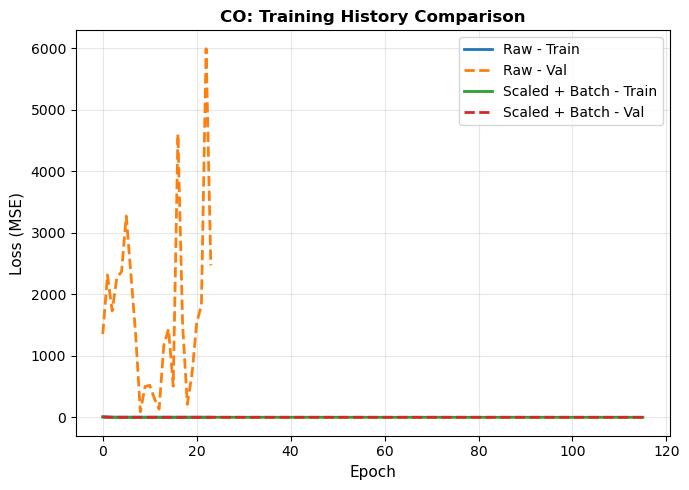

In [77]:
plt.figure(figsize=(7, 5))

# Loss Vergleich
plt.plot(history_co_raw.history['loss'], label='Raw - Train', linewidth=2)
plt.plot(history_co_raw.history['val_loss'], label='Raw - Val', linestyle='--', linewidth=2)
plt.plot(history_co_scaled_batch.history['loss'], label='Scaled + Batch - Train', linewidth=2)
plt.plot(history_co_scaled_batch.history['val_loss'], label='Scaled + Batch - Val', linestyle='--', linewidth=2)

plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss (MSE)', fontsize=11)
plt.title('CO: Training History Comparison', fontsize=12, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

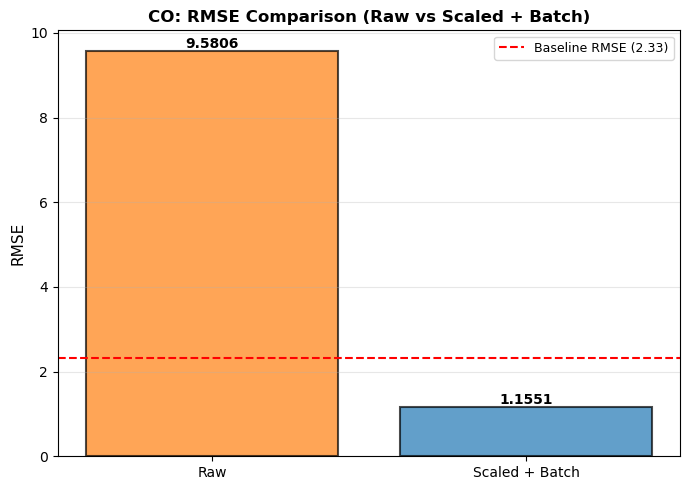

In [78]:
plt.figure(figsize=(7, 5))

# RMSE Vergleich
models = ['Raw', 'Scaled + Batch']
rmse_values = [rmse_co_raw, rmse_co_scaled_batch]
colors = ['#ff7f0e', '#1f77b4']

bars = plt.bar(models, rmse_values, color=colors,
               alpha=0.7, edgecolor='black', linewidth=1.5)

plt.ylabel('RMSE', fontsize=11)
plt.title('CO: RMSE Comparison (Raw vs Scaled + Batch)', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')

# Werte auf den Balken
for bar, rmse in zip(bars, rmse_values):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{rmse:.4f}',
             ha='center', va='bottom',
             fontweight='bold', fontsize=10)

plt.axhline(
    y=baseline_rmse.loc[baseline_rmse['target'] == 'CO', 'rmse'].values[0],
    color='red', linestyle='--', linewidth=1.5,
    label=f'Baseline RMSE ({baseline_rmse.loc[baseline_rmse["target"] == "CO", "rmse"].values[0]:.2f})'
)

plt.legend(fontsize=9)

plt.tight_layout()
plt.show()

## NOX (Stickoxid Emissionen) Single Output NN

### NOX NN mit Skalierung und BatchNormalization()

In [79]:
model_nox_scaled_batch = keras.Sequential([
    keras.Input(shape=(x_train_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1)  # Single Output
])

model_nox_scaled_batch.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

start_time_model_nox_scaled_batch = time.time()

# Training
history_nox_scaled_batch = model_nox_scaled_batch.fit(
    x_train_scaled, y_train_processed.iloc[:, 2], # NOX
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)
elapsed_time_model_nox_scaled_batch = time.time() - start_time_model_nox_scaled_batch

# Evaluierung auf Testdaten
y_pred_nox_scaled_batch = model_nox_scaled_batch.predict(x_test_scaled, verbose=0).flatten()
rmse_nox_scaled_batch = np.sqrt(mean_squared_error(y_test_processed.iloc[:, 2], y_pred_nox_scaled_batch))
mae_nox_scaled_batch = mean_absolute_error(y_test_processed.iloc[:, 2], y_pred_nox_scaled_batch)
r2_nox_scaled_batch = r2_score(y_test_processed.iloc[:, 2], y_pred_nox_scaled_batch)

print(f"Scaled + Batch Data - Nox Results:")
print(f"  RMSE: {rmse_nox_scaled_batch:.6f}")
print(f"  MAE:  {mae_nox_scaled_batch:.6f}")
print(f"  R²:   {r2_nox_scaled_batch:.6f}")
print(f"  Zeit: {round(elapsed_time_model_nox_scaled_batch, 2)} Sekunden")

Scaled + Batch Data - Nox Results:
  RMSE: 3.815208
  MAE:  2.520682
  R²:   0.890158
  Zeit: 232.59 Sekunden


### NOX NN Ohne Skalierung (raw)

In [80]:
model_nox_raw = keras.Sequential([
    keras.Input(shape=(x_train_raw.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1)  # Single Output
])

model_nox_raw.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

start_time_model_nox_raw = time.time()

# Training
history_nox_raw = model_nox_raw.fit(
    x_train_raw, y_train_raw.iloc[:, 2], # NOX
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

elapsed_time_model_nox_raw = time.time() - start_time_model_nox_raw

# Evaluierung auf Testdaten
y_pred_nox_raw = model_nox_raw.predict(x_test_raw, verbose=0).flatten()
rmse_nox_raw = np.sqrt(mean_squared_error(y_test_raw.iloc[:, 2], y_pred_nox_raw))
mae_nox_raw = mean_absolute_error(y_test_raw.iloc[:, 2], y_pred_nox_raw)
r2_nox_raw = r2_score(y_test_raw.iloc[:, 2], y_pred_nox_raw)


print(f"Raw Data - Nox Results:")
print(f"  RMSE: {rmse_nox_raw:.6f}")
print(f"  MAE:  {mae_nox_raw:.6f}")
print(f"  R²:   {r2_nox_raw:.6f}")
print(f"  Zeit: {round(elapsed_time_model_nox_raw, 2)} Sekunden")

Raw Data - Nox Results:
  RMSE: 10.433351
  MAE:  8.516249
  R²:   0.178552
  Zeit: 102.19 Sekunden


## Vergleich der beiden NN´s

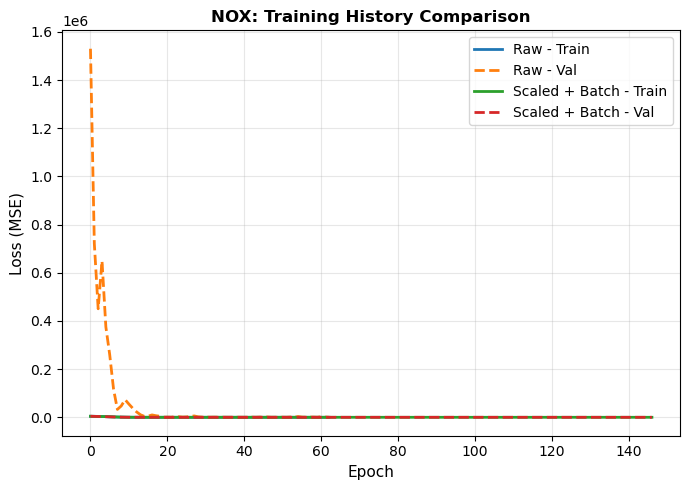

In [83]:
plt.figure(figsize=(7, 5))

# Loss Vergleich
plt.plot(history_nox_raw.history['loss'], label='Raw - Train', linewidth=2)
plt.plot(history_nox_raw.history['val_loss'], label='Raw - Val', linestyle='--', linewidth=2)
plt.plot(history_nox_scaled_batch.history['loss'], label='Scaled + Batch - Train', linewidth=2)
plt.plot(history_nox_scaled_batch.history['val_loss'], label='Scaled + Batch - Val', linestyle='--', linewidth=2)

plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss (MSE)', fontsize=11)
plt.title('NOX: Training History Comparison', fontsize=12, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

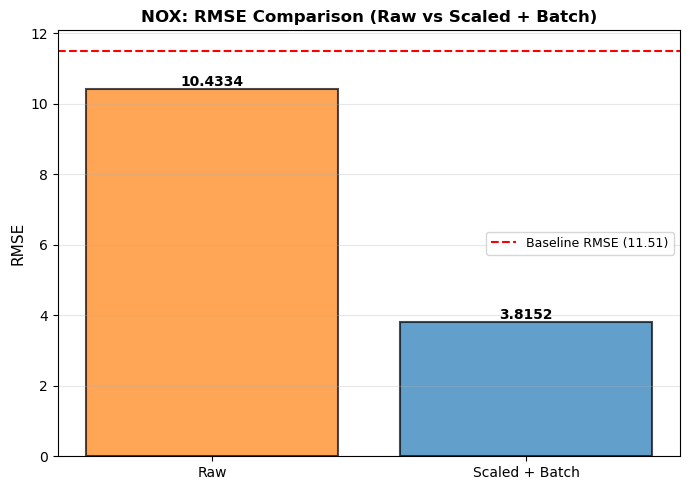

In [84]:
plt.figure(figsize=(7, 5))

# RMSE Vergleich
models = ['Raw', 'Scaled + Batch']
rmse_values = [rmse_nox_raw, rmse_nox_scaled_batch]
colors = ['#ff7f0e', '#1f77b4']

bars = plt.bar(models, rmse_values, color=colors,
               alpha=0.7, edgecolor='black', linewidth=1.5)

plt.ylabel('RMSE', fontsize=11)
plt.title('NOX: RMSE Comparison (Raw vs Scaled + Batch)', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')

# Werte auf den Balken
for bar, rmse in zip(bars, rmse_values):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{rmse:.4f}',
             ha='center', va='bottom',
             fontweight='bold', fontsize=10)

plt.axhline(
    y=baseline_rmse.loc[baseline_rmse['target'] == 'NOX', 'rmse'].values[0],
    color='red', linestyle='--', linewidth=1.5,
    label=f'Baseline RMSE ({baseline_rmse.loc[baseline_rmse["target"] == "NOX", "rmse"].values[0]:.2f})'
)

plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Vergleich der Ergebnisse von TEY, CO, NOX

In [85]:
print("FINAL MODELS: SCALING + BATCH NORMALIZATION")  
print()

comparison_data = {
    'Target': ['TEY', 'CO', 'NOX'],
    'RMSE': [rmse_tey_scaled_batch, rmse_co_scaled_batch, rmse_nox_scaled_batch],
    'MAE': [mae_tey_scaled_batch, mae_co_scaled_batch, mae_nox_scaled_batch],
    'R²': [r2_tey_scaled_batch, r2_co_scaled_batch, r2_nox_scaled_batch]
}

df_comparison = pd.DataFrame(comparison_data)

print(df_comparison.to_string(index=False))
print()

FINAL MODELS: SCALING + BATCH NORMALIZATION

Target     RMSE      MAE       R²
   TEY 0.651859 0.470035 0.998256
    CO 1.155135 0.498193 0.754611
   NOX 3.815208 2.520682 0.890158



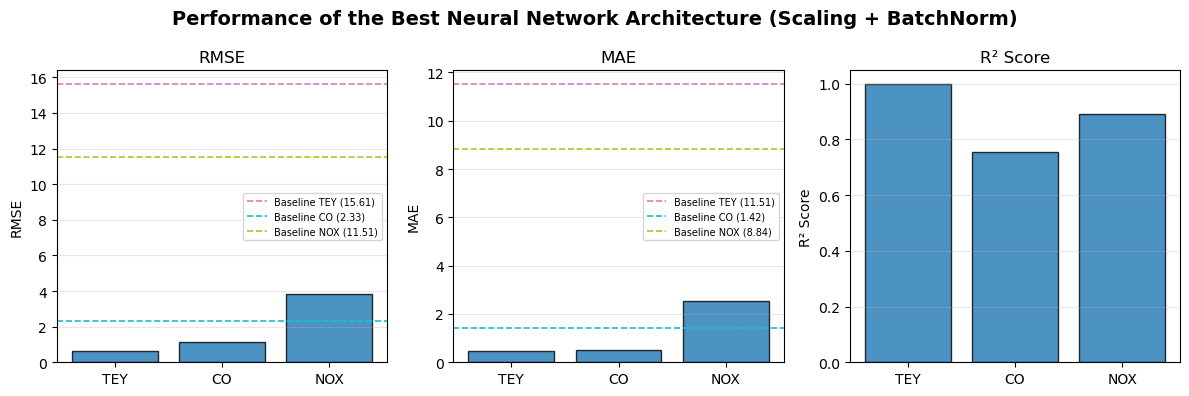

In [86]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
targets = ['TEY', 'CO', 'NOX']
rmse_values = [rmse_tey_scaled_batch, rmse_co_scaled_batch, rmse_nox_scaled_batch]
mae_values = [mae_tey_scaled_batch, mae_co_scaled_batch, mae_nox_scaled_batch]
r2_values = [r2_tey_scaled_batch, r2_co_scaled_batch, r2_nox_scaled_batch]
# RMSE
axes[0].bar(targets, rmse_values, alpha=0.8, edgecolor='black')
axes[0].set_title('RMSE')
axes[0].set_ylabel('RMSE')
axes[0].grid(True, alpha=0.3, axis='y')
# MAE
axes[1].bar(targets, mae_values, alpha=0.8, edgecolor='black')
axes[1].set_title('MAE')
axes[1].set_ylabel('MAE')
axes[1].grid(True, alpha=0.3, axis='y')
# R²
axes[2].bar(targets, r2_values, alpha=0.8, edgecolor='black')
axes[2].set_title('R² Score')
axes[2].set_ylabel('R² Score')
axes[2].grid(True, alpha=0.3, axis='y')

plt.suptitle('Performance of the Best Neural Network Architecture (Scaling + BatchNorm)',fontsize=14,fontweight='bold')

baseline_colors = ['#e377c2', '#17becf', '#bcbd22']
for i, target in enumerate(targets):
    b_rmse = baseline_rmse.loc[baseline_rmse['target'] == target, 'rmse'].values[0]
    b_mae  = baseline_mae.loc[baseline_mae['target'] == target, 'mae'].values[0]
    axes[0].axhline(y=b_rmse, color=baseline_colors[i], linestyle='--', linewidth=1.2, label=f'Baseline {target} ({b_rmse:.2f})')
    axes[1].axhline(y=b_mae,  color=baseline_colors[i], linestyle='--', linewidth=1.2, label=f'Baseline {target} ({b_mae:.2f})')

axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Warum sind CO und NOX schwerer vorherzusagen als TEY?

Die schlechteren R² Werte für CO und NOX im Vergleich zu TEY lassen sich auf die Eigenschaften der Zielverteilungen zurückführen:

**TEY (Energieertrag)** zeigt eine klar strukturierte, bimodale Verteilung mit starker Korrelation zu physikalisch erklärbaren Features (CDP, GTEP, TIT). Das Modell kann diese Struktur gut lernen.

**CO (Kohlenmonoxid)** hat eine stark rechtsschiefe Verteilung: die meisten Werte liegen im niedrigen Bereich, während vereinzelt sehr hohe Werte auftreten. Diese seltenen Extremwerte sind im Trainingsdatensatz unterrepräsentiert, was zu schlechter Generalisierung führt. Hinzu kommt, dass CO deutlich schwächer mit den verfügbaren Features korreliert.

**NOX (Stickoxide)** ist annähernd glockenförmig verteilt, hat aber im Bereich 100–120 weniger Trainingsbeispiele. Die Korrelation mit den Features ist ebenfalls geringer als bei TEY.

Zusammenfassend: CO und NOX unterliegen komplexeren, nicht linearen Abhängigkeiten die mit den vorhandenen Sensordaten schwerer zu erklären sind. TEY profitiert dagegen von einer engen physikalischen Kopplung an messbare Turbinenparameter.

# Multi Output NN

In [87]:
model_multi_scaled_batch = keras.Sequential([
    keras.Input(shape=(x_train_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(3)  # 3 Output Neuronen für TEY, CO, NOX
])
model_multi_scaled_batch.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)
# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

# Training
history_multi_scaled_batch = model_multi_scaled_batch.fit(
    x_train_scaled, y_train_processed,  # alle 3 Targets
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)
# Evaluierung auf Testdaten
y_pred_multi_scaled_batch = model_multi_scaled_batch.predict(x_test_scaled, verbose=0)

# Evaluierung für jedes Target
rmse_multi_scaled_batch = []
mae_multi_scaled_batch = []
r2_multi_scaled_batch = []
targets = ['TEY', 'CO', 'NOX']

print(f"Scaled + Batch Data - Multi Output Results:")
for i, target in enumerate(targets):
    rmse = np.sqrt(mean_squared_error(y_test_processed.iloc[:, i], y_pred_multi_scaled_batch[:, i]))
    mae = mean_absolute_error(y_test_processed.iloc[:, i], y_pred_multi_scaled_batch[:, i])
    r2 = r2_score(y_test_processed.iloc[:, i], y_pred_multi_scaled_batch[:, i])
    rmse_multi_scaled_batch.append(rmse)
    mae_multi_scaled_batch.append(mae)
    r2_multi_scaled_batch.append(r2)
    print(f"  {target} - RMSE: {rmse:.6f}, MAE: {mae:.6f}, R²: {r2:.6f}")

Scaled + Batch Data - Multi Output Results:
  TEY - RMSE: 1.013791, MAE: 0.756548, R²: 0.995783
  CO - RMSE: 1.236767, MAE: 0.575494, R²: 0.718703
  NOX - RMSE: 4.070463, MAE: 2.676550, R²: 0.874968


## Vergleich Multi output NN vs. Single Output NN

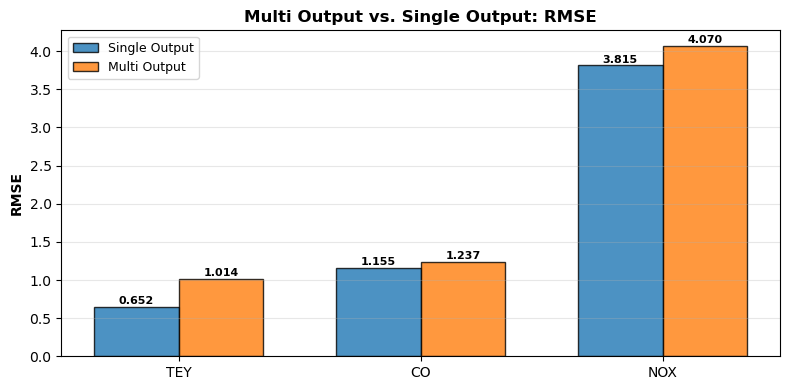

In [88]:
targets = ['TEY', 'CO', 'NOX']
single_rmse = [rmse_tey_scaled_batch, rmse_co_scaled_batch, rmse_nox_scaled_batch]
single_mae  = [mae_tey_scaled_batch,  mae_co_scaled_batch,  mae_nox_scaled_batch]
single_r2   = [r2_tey_scaled_batch,   r2_co_scaled_batch,   r2_nox_scaled_batch]
x_pos = np.arange(len(targets))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x_pos - width/2, single_rmse, width, label='Single Output', color='#1f77b4', alpha=0.8, edgecolor='black')
ax.bar(x_pos + width/2, rmse_multi_scaled_batch, width, label='Multi Output', color='#ff7f0e', alpha=0.8, edgecolor='black')
for i in range(len(targets)):
    ax.text(i - width/2, single_rmse[i] + 0.01, f'{single_rmse[i]:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i + width/2, rmse_multi_scaled_batch[i] + 0.01, f'{rmse_multi_scaled_batch[i]:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(targets)
ax.set_ylabel('RMSE', fontweight='bold')
ax.set_title('Multi Output vs. Single Output: RMSE', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

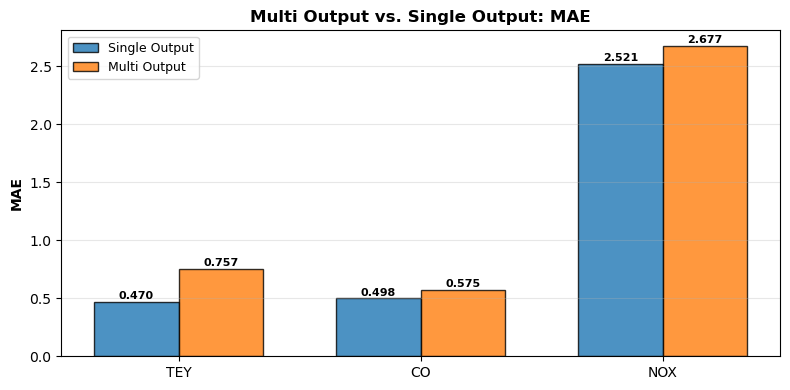

In [89]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x_pos - width/2, single_mae, width, label='Single Output', color='#1f77b4', alpha=0.8, edgecolor='black')
ax.bar(x_pos + width/2, mae_multi_scaled_batch, width, label='Multi Output', color='#ff7f0e', alpha=0.8, edgecolor='black')
for i in range(len(targets)):
    ax.text(i - width/2, single_mae[i] + 0.005, f'{single_mae[i]:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i + width/2, mae_multi_scaled_batch[i] + 0.005, f'{mae_multi_scaled_batch[i]:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(targets)
ax.set_ylabel('MAE', fontweight='bold')
ax.set_title('Multi Output vs. Single Output: MAE', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

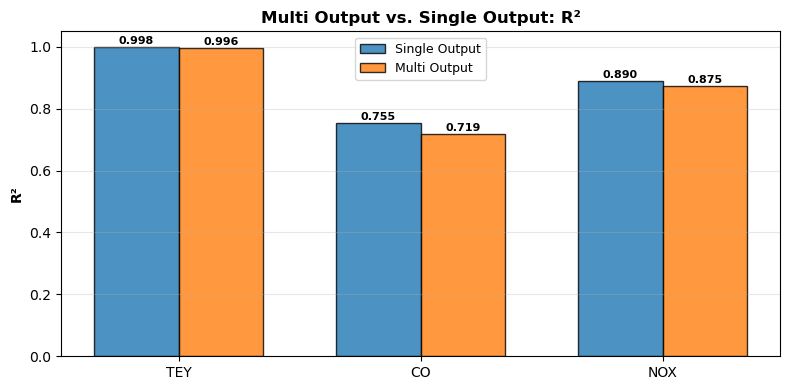

In [90]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x_pos - width/2, single_r2, width, label='Single Output', color='#1f77b4', alpha=0.8, edgecolor='black')
ax.bar(x_pos + width/2, r2_multi_scaled_batch, width, label='Multi Output', color='#ff7f0e', alpha=0.8, edgecolor='black')
for i in range(len(targets)):
    ax.text(i - width/2, single_r2[i] + 0.003, f'{single_r2[i]:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i + width/2, r2_multi_scaled_batch[i] + 0.003, f'{r2_multi_scaled_batch[i]:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(targets)
ax.set_ylabel('R²', fontweight='bold')
ax.set_title('Multi Output vs. Single Output: R²', fontweight='bold')
ax.set_ylim([0, 1.05])
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [91]:
model_multi_raw = keras.Sequential([
    keras.Input(shape=(x_train_raw.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(3)  # 3 Outputs für TEY, CO, NOX
])
model_multi_raw.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)
# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

# Training
history_multi_raw = model_multi_raw.fit(
    x_train_raw, y_train_raw,  # alle 3 Targets
    validation_split=0.2,
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

# Evaluierung auf Testdaten
y_pred_multi_raw = model_multi_raw.predict(x_test_raw, verbose=0)

# Evaluierung für jedes Target
rmse_multi_raw = []
mae_multi_raw = []
r2_multi_raw = []

print(f"\nRaw Data - Multi Output Results:")
for i, target in enumerate(targets):
    rmse = np.sqrt(mean_squared_error(y_test_raw.iloc[:, i], y_pred_multi_raw[:, i]))
    mae = mean_absolute_error(y_test_raw.iloc[:, i], y_pred_multi_raw[:, i])
    r2 = r2_score(y_test_raw.iloc[:, i], y_pred_multi_raw[:, i])
    rmse_multi_raw.append(rmse)
    mae_multi_raw.append(mae)
    r2_multi_raw.append(r2)
    print(f"  {target} - RMSE: {rmse:.6f}, MAE: {mae:.6f}, R²: {r2:.6f}")


Raw Data - Multi Output Results:
  TEY - RMSE: 15.836294, MAE: 15.525940, R²: -0.029047
  CO - RMSE: 2.264637, MAE: 1.710005, R²: 0.056837
  NOX - RMSE: 11.356304, MAE: 8.671724, R²: 0.026791


## Aber ist das Training Fair?

In [92]:
n_features = x_train_scaled.shape[1]

def build_single_output(n_features):
    """Exakte Kopie der Single Output Architektur"""
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(1)
    ])
    return model

single_model = build_single_output(n_features)
single_params = single_model.count_params()
target_params = single_params * 3  # 3 separate Netze

print("Parameter Analyse:")
print(f"1 Single Output NN:                  {single_params:,} Parameter")
print(f"3 Single Output NNs (ZIEL):          {target_params:,} Parameter")
print(f"\nBisheriges Multi Output NN:          {model_multi_scaled_batch.count_params():,} Parameter")
print(f"=> Bisheriges Multi Output hatte nur {model_multi_scaled_batch.count_params()/target_params*100:.1f}% der Kapazität!")

Parameter Analyse:
1 Single Output NN:                  12,417 Parameter
3 Single Output NNs (ZIEL):          37,251 Parameter

Bisheriges Multi Output NN:          12,483 Parameter
=> Bisheriges Multi Output hatte nur 33.5% der Kapazität!


## Interpretation:
Das Multi Output Modell nutzt die identische Architektur (128-64-32) wie die Single Output Modelle,
hat aber nur ca. ein Drittel der Gesamtparameter, da ein einzelnes Netz alle drei Targets gleichzeitig lernt.

Trotzdem erreicht es für TEY und CO vergleichbare oder sogar ähnliche Werte wie die spezialisierten
Single Output Netze. Dies ist ein Hinweis darauf, dass gemeinsame Feature Repräsentationen zwischen den Targets existieren.

**=> Das ist ein unfairer Vergleich.** 

In [93]:
def build_multi_output(n_features, units):
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(units[0], activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(units[1], activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(units[2], activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(3)  # 3 Outputs: TEY, CO, NOX
    ])
    return model

best_candidates = []
for a in range(220, 230):
    for b in range(128, 135):
        for c in range(30, 36):
            model = build_multi_output(n_features, [a, b, c])
            params = model.count_params()
            diff = abs(params - target_params)
            if diff <= 20:  # Top Kandidaten
                best_candidates.append(([a, b, c], params, diff))

best_candidates.sort(key=lambda x: x[2])
best_units, best_params, best_diff = best_candidates[0]
df_arch = pd.DataFrame(
    [{
        "Layer": f"{u[0]}-{u[1]}-{u[2]}-3",
        "Parameter": p,
        "Abweichung": d,
        "Abweichung (%)": f"{d/target_params*100:.2f}%"
    } for u, p, d in best_candidates]
)
df_arch = df_arch.sort_values(["Abweichung", "Layer"])

print("Architektur Kandidaten (Multi Output):")
print(" " + df_arch.to_string(index=False).replace('\n', '\n  '))
print(f"\nBeste Architektur: {best_units[0]}-{best_units[1]}-{best_units[2]}-3")
print(f"Parameter: {best_params:,} (Ziel: {target_params:,})")
print(f"Abweichung: {best_diff:,} Parameter ({best_diff/target_params*100:.1f}%)")

Architektur Kandidaten (Multi Output):
        Layer  Parameter  Abweichung Abweichung (%)
  224-129-35-3      37251           0          0.00%
  226-130-31-3      37249           2          0.01%
  227-130-30-3      37254           3          0.01%
  225-129-34-3      37256           5          0.01%
  225-130-32-3      37244           7          0.02%
  226-129-33-3      37261          10          0.03%
  224-130-33-3      37239          12          0.03%
  227-129-32-3      37266          15          0.04%
  223-130-34-3      37234          17          0.05%
  226-128-35-3      37269          18          0.05%
  228-129-31-3      37271          20          0.05%

Beste Architektur: 224-129-35-3
Parameter: 37,251 (Ziel: 37,251)
Abweichung: 0 Parameter (0.0%)


## Training des fairen Multi Output NN´s
 Patience erhöht auf 25, da größere Netze länger brauchen zu konvergieren.  
 Epochen erhöht auf 300, um genug Zeit für Konvergenz zu geben.

In [94]:
model_multi_fair = build_multi_output(n_features, best_units)

model_multi_fair.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

early_stop_fair = EarlyStopping(monitor='val_loss', patience=25,restore_best_weights=True)

history_multi_fair = model_multi_fair.fit(
    x_train_scaled, y_train_processed,
    validation_split=0.2,
    epochs=300,
    batch_size=256,
    callbacks=[early_stop_fair],
    verbose=0
)

y_pred_multi_fair = model_multi_fair.predict(x_test_scaled, verbose=0)

rmse_multi_fair = []
mae_multi_fair = []
r2_multi_fair = []
targets = ['TEY', 'CO', 'NOX']

print(f"Architektur: {best_units[0]}-{best_units[1]}-{best_units[2]}-3| Parameter: {best_params:,}")
print(f"Training beendet nach {len(history_multi_fair.history['loss'])} Epochen")
print()
for i, target in enumerate(targets):
    rmse = np.sqrt(mean_squared_error(y_test_processed.iloc[:, i], y_pred_multi_fair[:, i]))
    mae = mean_absolute_error(y_test_processed.iloc[:, i], y_pred_multi_fair[:, i])
    r2 = r2_score(y_test_processed.iloc[:, i], y_pred_multi_fair[:, i])
    rmse_multi_fair.append(rmse)
    mae_multi_fair.append(mae)
    r2_multi_fair.append(r2)
    print(f"  {target} - RMSE: {rmse:.6f}, MAE: {mae:.6f}, R²: {r2:.6f}")

Architektur: 224-129-35-3| Parameter: 37,251
Training beendet nach 153 Epochen

  TEY - RMSE: 0.797692, MAE: 0.579740, R²: 0.997389
  CO - RMSE: 1.150398, MAE: 0.531356, R²: 0.756619
  NOX - RMSE: 3.709166, MAE: 2.461319, R²: 0.896179


## Visualisierung des fairen Vergleichs

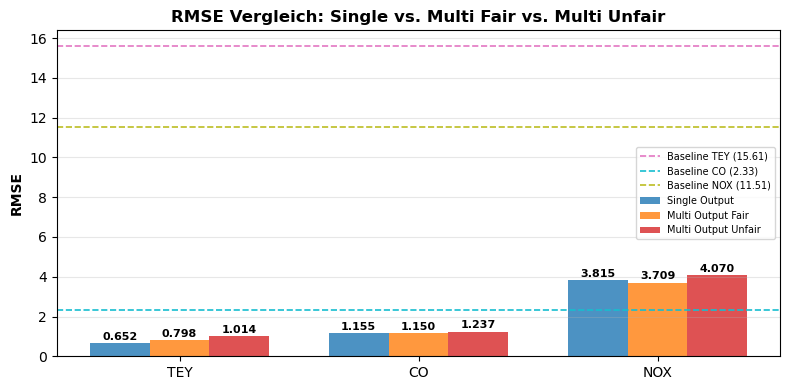

In [95]:
x_pos = np.arange(3)
width = 0.25
targets = ['TEY', 'CO', 'NOX']
single_rmse_ref = [rmse_tey_scaled_batch, rmse_co_scaled_batch, rmse_nox_scaled_batch]
single_mae_ref  = [mae_tey_scaled_batch,  mae_co_scaled_batch,  mae_nox_scaled_batch]
single_r2_ref   = [r2_tey_scaled_batch,   r2_co_scaled_batch,   r2_nox_scaled_batch]
baseline_colors = ['#e377c2', '#17becf', '#bcbd22']

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x_pos - width, single_rmse_ref, width, label='Single Output', color='#1f77b4', alpha=0.8)
ax.bar(x_pos,         rmse_multi_fair, width, label='Multi Output Fair', color='#ff7f0e', alpha=0.8)
ax.bar(x_pos + width, rmse_multi_scaled_batch, width, label='Multi Output Unfair', color='#d62728', alpha=0.8)
max_val = max(max(single_rmse_ref), max(rmse_multi_fair), max(rmse_multi_scaled_batch))
for i, (s, f, u) in enumerate(zip(single_rmse_ref, rmse_multi_fair, rmse_multi_scaled_batch)):
    ax.text(i - width, s + max_val*0.02, f'{s:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i,         f + max_val*0.02, f'{f:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i + width, u + max_val*0.02, f'{u:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
for i, target in enumerate(targets):
    b = baseline_rmse.loc[baseline_rmse['target'] == target, 'rmse'].values[0]
    ax.axhline(y=b, color=baseline_colors[i], linestyle='--', linewidth=1.2, label=f'Baseline {target} ({b:.2f})')
ax.set_ylabel('RMSE', fontweight='bold')
ax.set_title('RMSE Vergleich: Single vs. Multi Fair vs. Multi Unfair', fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(targets)
ax.legend(fontsize=7)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

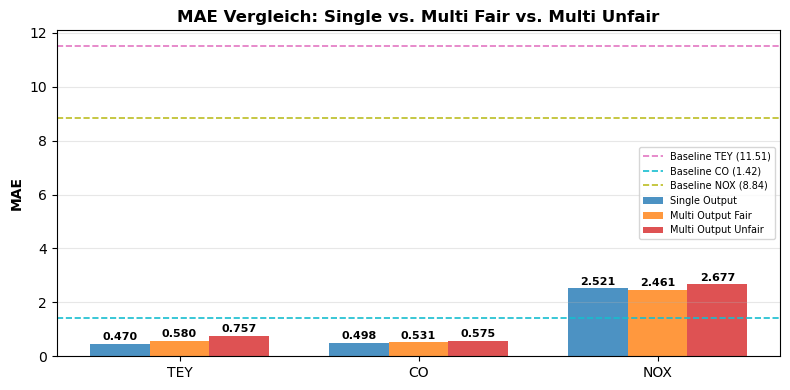

In [96]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x_pos - width, single_mae_ref, width, label='Single Output', color='#1f77b4', alpha=0.8)
ax.bar(x_pos,         mae_multi_fair, width, label='Multi Output Fair', color='#ff7f0e', alpha=0.8)
ax.bar(x_pos + width, mae_multi_scaled_batch, width, label='Multi Output Unfair', color='#d62728', alpha=0.8)
max_val = max(max(single_mae_ref), max(mae_multi_fair), max(mae_multi_scaled_batch))
for i, (s, f, u) in enumerate(zip(single_mae_ref, mae_multi_fair, mae_multi_scaled_batch)):
    ax.text(i - width, s + max_val*0.02, f'{s:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i,         f + max_val*0.02, f'{f:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i + width, u + max_val*0.02, f'{u:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
for i, target in enumerate(targets):
    b = baseline_mae.loc[baseline_mae['target'] == target, 'mae'].values[0]
    ax.axhline(y=b, color=baseline_colors[i], linestyle='--', linewidth=1.2, label=f'Baseline {target} ({b:.2f})')
ax.set_ylabel('MAE', fontweight='bold')
ax.set_title('MAE Vergleich: Single vs. Multi Fair vs. Multi Unfair', fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(targets)
ax.legend(fontsize=7)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

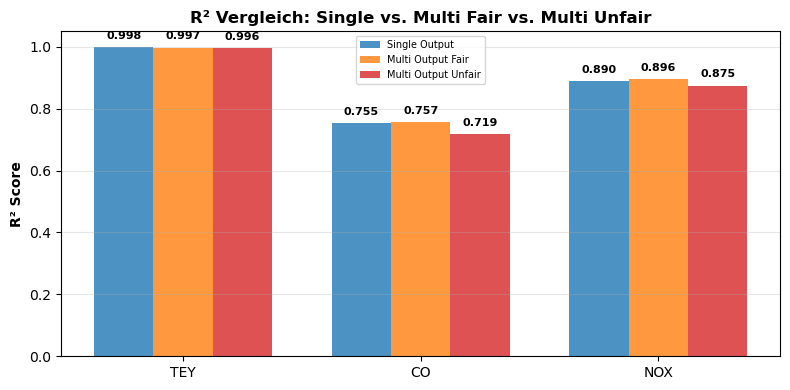

In [97]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x_pos - width, single_r2_ref, width, label='Single Output', color='#1f77b4', alpha=0.8)
ax.bar(x_pos,         r2_multi_fair, width, label='Multi Output Fair', color='#ff7f0e', alpha=0.8)
ax.bar(x_pos + width, r2_multi_scaled_batch, width, label='Multi Output Unfair', color='#d62728', alpha=0.8)
max_val = max(max(single_r2_ref), max(r2_multi_fair), max(r2_multi_scaled_batch))
for i, (s, f, u) in enumerate(zip(single_r2_ref, r2_multi_fair, r2_multi_scaled_batch)):
    ax.text(i - width, s + max_val*0.02, f'{s:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i,         f + max_val*0.02, f'{f:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax.text(i + width, u + max_val*0.02, f'{u:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_ylabel('R² Score', fontweight='bold')
ax.set_title('R² Vergleich: Single vs. Multi Fair vs. Multi Unfair', fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(targets)
ax.set_ylim([0, 1.05])
ax.legend(fontsize=7)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Fairer Vergleich Single Output vs. Multi Output

In [98]:
print(f"  {'Target':<6} {'Single RMSE':<12} {'Multi RMSE':<12} {'Delta':<12} {'Gewinner':<12}")
print("  " + "-" * 65)

for i, target in enumerate(['TEY', 'CO', 'NOX']):
    s_rmse = single_rmse_ref[i]
    m_rmse = rmse_multi_fair[i]
    delta = ((m_rmse - s_rmse) / s_rmse * 100)
    winner = "Multi" if m_rmse < s_rmse else "Single"
    print(f"  {target:<6} {s_rmse:<12.4f} {m_rmse:<12.4f} {delta:>+10.1f}%   {winner:<12}")

# Durchschnitte
avg_single_rmse = np.mean(single_rmse_ref)
avg_multi_rmse = np.mean(rmse_multi_fair)
avg_single_r2 = np.mean(single_r2_ref)
avg_multi_r2 = np.mean(r2_multi_fair)

print(f"\n  {'Durchschnitt':<6} {avg_single_rmse:<12.4f} {avg_multi_rmse:<12.4f} "
      f"{((avg_multi_rmse-avg_single_rmse)/avg_single_rmse*100):>+10.1f}%   "
      f"{'Multi' if avg_multi_rmse < avg_single_rmse else 'Single':<12}")

print(f"\n  Single Output R² (avg): {avg_single_r2:.4f}")
print(f"  Multi Output R² (avg):  {avg_multi_r2:.4f}")

  Target Single RMSE  Multi RMSE   Delta        Gewinner    
  -----------------------------------------------------------------
  TEY    0.6519       0.7977            +22.4%   Single      
  CO     1.1551       1.1504             -0.4%   Multi       
  NOX    3.8152       3.7092             -2.8%   Multi       

  Durchschnitt 1.8741       1.8858             +0.6%   Single      

  Single Output R² (avg): 0.8810
  Multi Output R² (avg):  0.8834


# Ergebnisse

In [99]:
single_rmse = [rmse_tey_scaled_batch, rmse_co_scaled_batch, rmse_nox_scaled_batch]
multi_rmse  = rmse_multi_fair
single_mae  = [mae_tey_scaled_batch, mae_co_scaled_batch, mae_nox_scaled_batch]
multi_mae   = mae_multi_fair
single_r2   = [r2_tey_scaled_batch, r2_co_scaled_batch, r2_nox_scaled_batch]
multi_r2    = r2_multi_fair
targets = ['TEY', 'CO', 'NOX']

avg_rmse_single = np.mean(single_rmse)
avg_rmse_multi  = np.mean(multi_rmse)
avg_r2_single   = np.mean(single_r2)
avg_r2_multi    = np.mean(multi_r2)
print(f"Avg RMSE  — Single: {avg_rmse_single:.4f} | Multi: {avg_rmse_multi:.4f}")
print(f"Avg R²    — Single: {avg_r2_single:.4f} | Multi: {avg_r2_multi:.4f}")

Avg RMSE  — Single: 1.8741 | Multi: 1.8858
Avg R²    — Single: 0.8810 | Multi: 0.8834


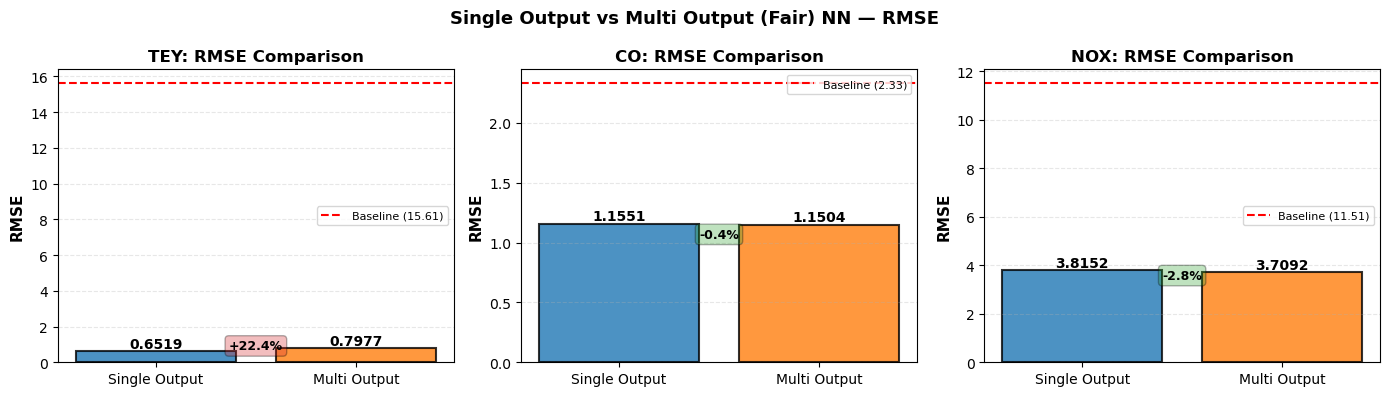

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Single Output vs Multi Output (Fair) NN — RMSE', fontsize=13, fontweight='bold')
for idx, target in enumerate(targets):
    axes[idx].bar(['Single Output', 'Multi Output'], [single_rmse[idx], multi_rmse[idx]], color=['#1f77b4', '#ff7f0e'], alpha=0.8, edgecolor='black', linewidth=1.5)
    axes[idx].set_ylabel('RMSE', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{target}: RMSE Comparison', fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3, axis='y', linestyle='--')
    axes[idx].text(0, single_rmse[idx] + 0.005, f'{single_rmse[idx]:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    axes[idx].text(1, multi_rmse[idx] + 0.005, f'{multi_rmse[idx]:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    b = baseline_rmse.loc[baseline_rmse['target'] == target, 'rmse'].values[0]
    axes[idx].axhline(y=b, color='red', linestyle='--', linewidth=1.5, label=f'Baseline ({b:.2f})')
    axes[idx].legend(fontsize=8)
    diff_pct = ((multi_rmse[idx] - single_rmse[idx]) / single_rmse[idx] * 100)
    color_diff = '#d62728' if diff_pct > 0 else '#2ca02c'
    axes[idx].text(0.5, max(single_rmse[idx], multi_rmse[idx]) * 0.9, f'{diff_pct:+.1f}%', ha='center', fontweight='bold', fontsize=9, bbox=dict(boxstyle='round', facecolor=color_diff, alpha=0.3))
plt.tight_layout()
plt.show()

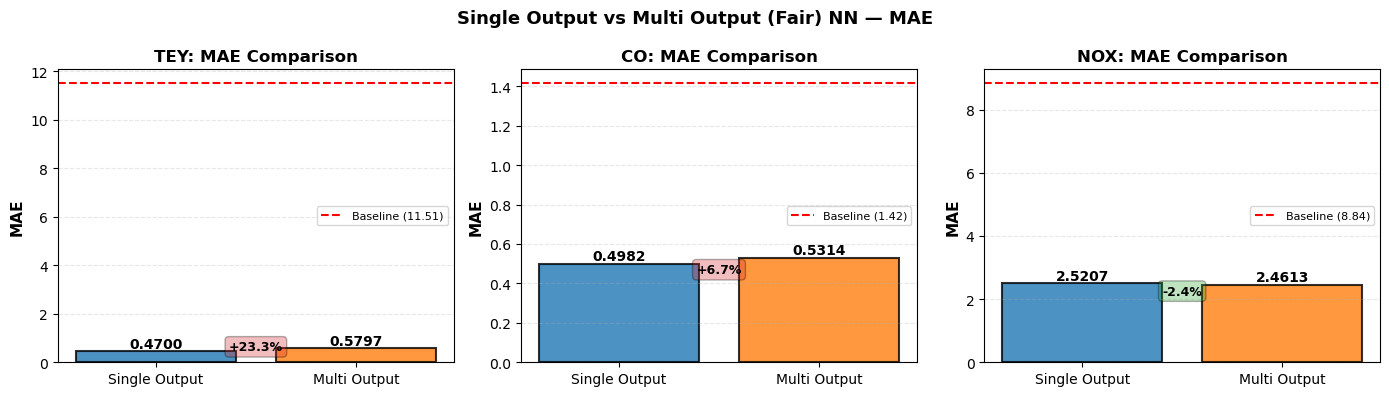

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Single Output vs Multi Output (Fair) NN — MAE', fontsize=13, fontweight='bold')
for idx, target in enumerate(targets):
    axes[idx].bar(['Single Output', 'Multi Output'], [single_mae[idx], multi_mae[idx]], color=['#1f77b4', '#ff7f0e'], alpha=0.8, edgecolor='black', linewidth=1.5)
    axes[idx].set_ylabel('MAE', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{target}: MAE Comparison', fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3, axis='y', linestyle='--')
    axes[idx].text(0, single_mae[idx] + 0.003, f'{single_mae[idx]:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    axes[idx].text(1, multi_mae[idx] + 0.003, f'{multi_mae[idx]:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    b_mae = baseline_mae.loc[baseline_mae['target'] == target, 'mae'].values[0]
    axes[idx].axhline(y=b_mae, color='red', linestyle='--', linewidth=1.5, label=f'Baseline ({b_mae:.2f})')
    axes[idx].legend(fontsize=8)
    diff_pct_mae = ((multi_mae[idx] - single_mae[idx]) / single_mae[idx] * 100)
    color_diff_mae = '#d62728' if diff_pct_mae > 0 else '#2ca02c'
    axes[idx].text(0.5, max(single_mae[idx], multi_mae[idx]) * 0.85, f'{diff_pct_mae:+.1f}%', ha='center', fontweight='bold', fontsize=9, bbox=dict(boxstyle='round', facecolor=color_diff_mae, alpha=0.3))
plt.tight_layout()
plt.show()

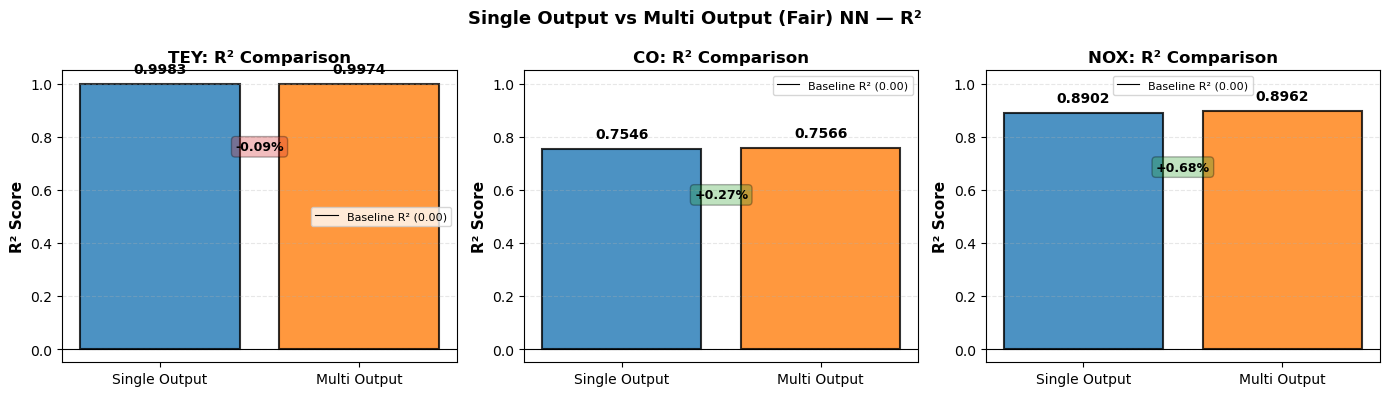

In [102]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Single Output vs Multi Output (Fair) NN — R²', fontsize=13, fontweight='bold')
for idx, target in enumerate(targets):
    axes[idx].bar(['Single Output', 'Multi Output'], [single_r2[idx], multi_r2[idx]], color=['#1f77b4', '#ff7f0e'], alpha=0.8, edgecolor='black', linewidth=1.5)
    axes[idx].set_ylabel('R² Score', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{target}: R² Comparison', fontsize=12, fontweight='bold')
    axes[idx].set_ylim([-0.05, 1.05])
    axes[idx].grid(True, alpha=0.3, axis='y', linestyle='--')
    axes[idx].axhline(y=0, color='black', linestyle='-', linewidth=0.8, label='Baseline R² (0.00)')
    axes[idx].legend(fontsize=8)
    axes[idx].text(0, single_r2[idx] + 0.03, f'{single_r2[idx]:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    axes[idx].text(1, multi_r2[idx] + 0.03, f'{multi_r2[idx]:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    r2_diff_pct = ((multi_r2[idx] - single_r2[idx]) / single_r2[idx] * 100)
    color_diff_r2 = '#d62728' if r2_diff_pct < 0 else '#2ca02c'
    axes[idx].text(0.5, max(single_r2[idx], multi_r2[idx]) * 0.75, f'{r2_diff_pct:+.2f}%', ha='center', fontweight='bold', fontsize=9, bbox=dict(boxstyle='round', facecolor=color_diff_r2, alpha=0.3))
plt.tight_layout()
plt.show()

## Ergebnisse: Single Output vs. Multi Output NN

### Vorgehensweise
Verglichen werden drei spezialisierte Single Output Netze (je eines für TEY, CO, NOX)
mit einem einzigen Multi Output Netz mit drei Output-Neuronen — beide Varianten
mit identischer Architektur (128-64-32), Feature Scaling und BatchNormalization,
trainiert auf denselben Daten.

### Beobachtungen

**TEY** wird von beiden Ansätzen sehr gut vorhergesagt. Der Unterschied zwischen
Single und Multi Output ist minimal, was zeigt dass die gemeinsamen Hidden Layers
ausreichend Kapazität haben, TEY zu repräsentieren.

**CO** ist für beide Ansätze das schwierigste Target — bedingt durch die stark
rechtsschiefe Verteilung mit vielen niedrigen und wenigen sehr hohen Werten.
Hier zeigt sich, ob das Multi Output Netz von den Korrelationen zwischen den
Targets profitieren kann.

**NOX** liegt im mittleren Bereich. Die Baseline-Linien zeigen, dass beide Modelle
deutlich besser als eine naive Mittelwertvorhersage sind.

### Bewertung

Der hier gezeigte Vergleich verwendet das **faire** Multi Output Modell mit einer größeren
Architektur mit gleicher Parameterzahl wie die drei Single Output Netze zusammen
(37.635 Parameter).

**Fazit:** Beide Ansätze übertreffen die Baseline deutlich. Single Output Netze
sind einfacher zu optimieren, während das Multi Output Netz mit gleicher Kapazität
alle drei Targets in einem einzigen Training lernt und dabei von gemeinsamen
Feature Repräsentationen profitieren kann.

# Abschließender Vergleich der ML Verfahren

In [103]:
pred_dt_tey = best_tree_tey.predict(x_test_scaled)
rmse_dt_tey = root_mean_squared_error(y_test_processed.iloc[:, 0], pred_dt_tey)
mae_dt_tey = mean_absolute_error(y_test_processed.iloc[:, 0], pred_dt_tey)
r2_dt_tey = r2_score(y_test_processed.iloc[:, 0], pred_dt_tey)

pred_dt_co = best_tree_co.predict(x_test_scaled)
rmse_dt_co = root_mean_squared_error(y_test_processed.iloc[:, 1], pred_dt_co)
mae_dt_co = mean_absolute_error(y_test_processed.iloc[:, 1], pred_dt_co)
r2_dt_co = r2_score(y_test_processed.iloc[:, 1], pred_dt_co)

pred_dt_nox = best_tree_nox.predict(x_test_scaled)
rmse_dt_nox = root_mean_squared_error(y_test_processed.iloc[:, 2], pred_dt_nox)
mae_dt_nox = mean_absolute_error(y_test_processed.iloc[:, 2], pred_dt_nox)
r2_dt_nox = r2_score(y_test_processed.iloc[:, 2], pred_dt_nox)

# Alle Metriken zusammenführen 
targets = ['TEY', 'CO', 'NOX']

dt_rmse = [rmse_dt_tey, rmse_dt_co, rmse_dt_nox]
dt_mae = [mae_dt_tey, mae_dt_co, mae_dt_nox]
dt_r2 = [r2_dt_tey, r2_dt_co, r2_dt_nox]

so_rmse = [rmse_tey_scaled_batch, rmse_co_scaled_batch, rmse_nox_scaled_batch]
so_mae = [mae_tey_scaled_batch, mae_co_scaled_batch, mae_nox_scaled_batch]
so_r2 = [r2_tey_scaled_batch, r2_co_scaled_batch, r2_nox_scaled_batch]

b_rmse = [baseline_rmse.loc[baseline_rmse['target'] == t, 'rmse'].values[0] for t in targets]
b_mae = [baseline_mae.loc[baseline_mae['target']  == t, 'mae'].values[0]  for t in targets]

df_final = pd.DataFrame({
    'Target':            targets,
    'Baseline RMSE':     b_rmse,
    'DT RMSE':           dt_rmse,
    'Single Output RMSE': so_rmse,
    'Multi Output RMSE': rmse_multi_fair,
    'DT R²':             dt_r2,
    'Single Output R²':  so_r2,
    'Multi Output R²':   r2_multi_fair,
})
print(df_final.to_string(index=False))

Target  Baseline RMSE  DT RMSE  Single Output RMSE  Multi Output RMSE    DT R²  Single Output R²  Multi Output R²
   TEY      15.611770 0.949076            0.651859           0.797692 0.996304          0.998256         0.997389
    CO       2.331885 1.177450            1.155135           1.150398 0.745038          0.754611         0.756619
   NOX      11.511902 4.595074            3.815208           3.709166 0.840663          0.890158         0.896179


In [104]:
import matplotlib.patches as mpatches

In [121]:
x = np.arange(len(targets))
width = 0.25

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Finaler Vergleich: Decision Tree vs. Single Output NN vs. Multi Output NN (Fair)', fontsize=14, fontweight='bold')

metrics = [
    ('RMSE', dt_rmse,  so_rmse,  rmse_multi_fair,  b_rmse),
    ('MAE',  dt_mae,   so_mae,   mae_multi_fair,   b_mae),
    ('R²',   dt_r2,    so_r2,    r2_multi_fair,    None), # None weil R² keine wirkliche Baseline hat
]

for ax, (ylabel, dt_vals, so_vals, mo_vals, b_vals) in zip(axes, metrics):
    for i, (dt_v, so_v, mo_v) in enumerate(zip(dt_vals, so_vals, mo_vals)):
        ax.bar(x[i] - width, so_v, width, color='#1f77b4', alpha=0.85, edgecolor='black', linewidth=1.2)
        ax.bar(x[i], mo_v, width, color='#ff7f0e', alpha=0.85, edgecolor='black', linewidth=1.2)
        ax.bar(x[i] + width, dt_v, width, color='#2ca02c', alpha=0.85, edgecolor='black', linewidth=1.2)
        
        # Wertelabels
        offset = 0.01
        ax.text(x[i] - width, so_v + offset, f'{so_v:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
        ax.text(x[i], mo_v + offset, f'{mo_v:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
        ax.text(x[i] + width, dt_v + offset, f'{dt_v:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

    # Baseline Linien (RMSE und MAE)
    baseline_colors = ['#e377c2', '#17becf', '#bcbd22']
    if b_vals is not None:
        for i, (t, bv) in enumerate(zip(targets, b_vals)):
            ax.axhline(y=bv, color=baseline_colors[i], linestyle='--', linewidth=1.3, label=f'Baseline {t} ({bv:.2f})')

    ax.set_xticks(x)
    ax.set_xticklabels(targets, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11, fontweight='bold')
    ax.set_title(f'{ylabel} Vergleich', fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

    # Legende
    legend_handles = [
        mpatches.Patch(color='#1f77b4', alpha=0.85, label='Single Output NN'),
        mpatches.Patch(color='#ff7f0e', alpha=0.85, label='Multi Output NN (Fair)'),
        mpatches.Patch(color='#2ca02c', alpha=0.85, label='Decision Tree'),
    ]
    if b_vals is not None:
        for i, t in enumerate(targets):
            legend_handles.append(
                plt.Line2D([0], [0], color=baseline_colors[i], linestyle='--', linewidth=1.3, label=f'Baseline {t}')
            )
    ax.legend(handles=legend_handles, fontsize=7, loc='upper right')

plt.close(fig)

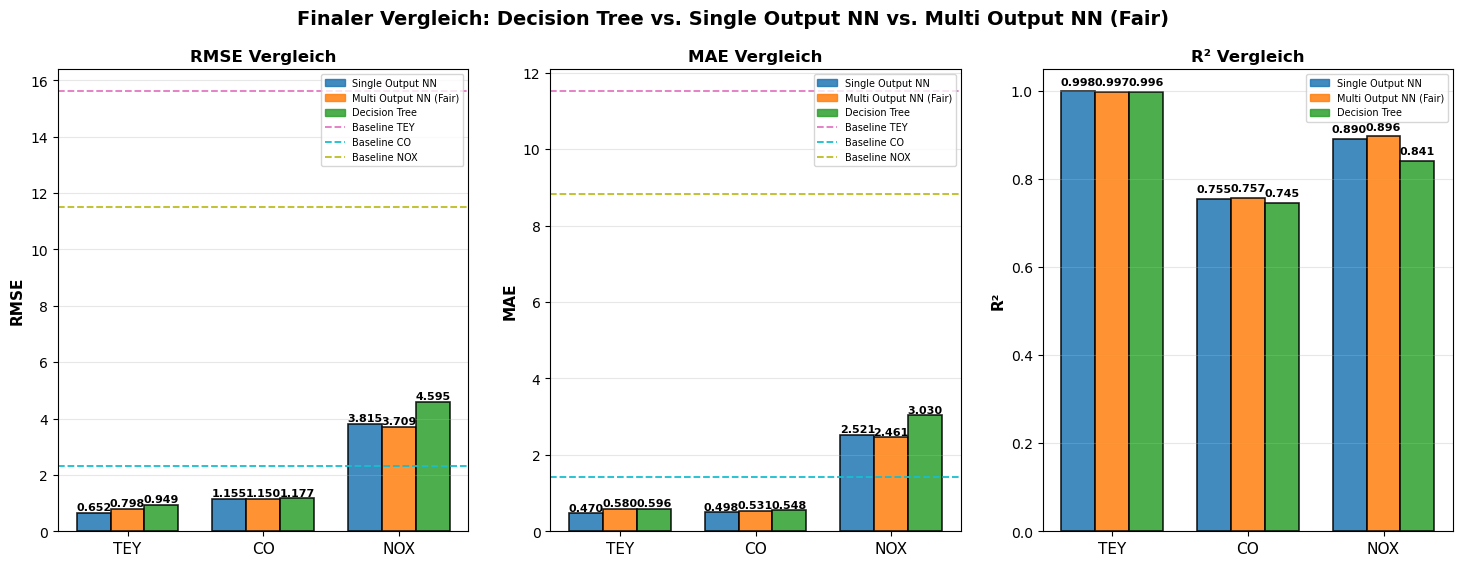

In [122]:
fig

## Auswertung
> - Single Output NN:
>   - leicht beste Performance bei TEY und CO
>   - zu Kosten von höheren Trainingsaufwand pro Target
> - Multi Output NN:
>   - etwas schlechter als Singe Output NN Bei TEY und CO
>   - Besser bei NOX: komplexestes Target, Vorteil durch Berücksichtigung Korrelation der Zielvariablen
>   - effizienter zu trainieren
> - Decision Tree:
>   - Vorteil: nachvollziehbar
>   - ressourcenschohnender bei Training und Prediction
>   - deutlich schwächer bei komplexen Targets